# PJM Hourly Energy Consumption Forecast 

## Business objective
Analyze PJM hourly electricity consumption in MW, understand its time-based patterns, prepare a reliable base dataset for modeling, and support the later requirements of:
- using the **last year as the test set**,
- studying hourly, seasonal and long-term patterns,
- considering holiday effects where appropriate, and
- producing a **30-day forecast**.

# Week 1 - EDA
 
**Week 1 milestone:** Exploratory Data Analysis (EDA)

## 1. Import libraries and load the dataset


In [1]:
# Purpose: import the libraries required for data loading, numerical operations, and plotting.
# Read the original Excel dataset and convert Datetime to pandas datetime so time-based analysis is reliable.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("PJMW_MW_Hourly.xlsx")
df["Datetime"] = pd.to_datetime(df["Datetime"])

### Raw data preview


In [2]:
# Quick preview of the raw dataset to verify that the expected columns and values were loaded correctly.

df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


## 2. Basic dataset inspection


### Dataset shape and data types


In [3]:
# Check the dataset size and data types before cleaning.
# This confirms how many observations are available and whether Datetime/consumption are stored in usable types.

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

Shape: (143206, 2)

Data types:
Datetime    datetime64[us]
PJMW_MW              int64
dtype: object


### Missing values and duplicates


In [4]:
# Check missing values and exact duplicate rows first.
# Then check duplicate timestamps separately 
# because duplicate timestamps can affect time-series calculations even when full rows are different.

print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Datetime values:", df["Datetime"].duplicated().sum())

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows: 0
Duplicate Datetime values: 4


### Date range and descriptive statistics


In [5]:
# Establish the time span covered by the dataset and inspect the distribution of electricity consumption.
# Descriptive statistics help identify the typical level, spread, minimum, and maximum before deeper EDA.

print("Date range:")
print(df["Datetime"].min(), "to", df["Datetime"].max())

print("\nDescriptive statistics for PJMW_MW:")
print(df["PJMW_MW"].describe())

Date range:
2002-04-01 01:00:00 to 2018-08-03 00:00:00

Descriptive statistics for PJMW_MW:
count    143206.000000
mean       5602.375089
std         979.142872
min         487.000000
25%        4907.000000
50%        5530.000000
75%        6252.000000
max        9594.000000
Name: PJMW_MW, dtype: float64


### Initial finding

The raw dataset contains **143,206 rows and 2 columns**. There are no null values and no fully duplicated rows, but duplicate timestamps require investigation before time-series analysis.


## 3. Chronological integrity and timestamp anomalies


### Sort chronologically and inspect time intervals


In [6]:
# Sort by time before calculating differences between consecutive observations.
# Time gaps are then used to identify duplicate timestamps, normal hourly intervals, clock-change transitions, 
# and other irregularities.

df = df.sort_values("Datetime").reset_index(drop=True)
time_diff = df["Datetime"].diff()

print("1-hour intervals:", (time_diff == pd.Timedelta(hours=1)).sum())
print("2-hour gaps:", (time_diff == pd.Timedelta(hours=2)).sum())
print("Duplicate timestamp transitions:", (time_diff == pd.Timedelta(0)).sum())
print("Other interval changes:", (~time_diff.isin([pd.Timedelta(hours=1), pd.Timedelta(hours=2), pd.Timedelta(0)])).sum())

1-hour intervals: 143171
2-hour gaps: 30
Duplicate timestamp transitions: 4
Other interval changes: 1


### Duplicate timestamp records


In [7]:
# Display every record involved in a duplicated timestamp so we can inspect the actual consumption values.
# This is important before deciding how duplicate timestamps should be handled.

duplicate_records = df[df["Datetime"].duplicated(keep= False)] # To get all the occurrence of duplicate values
print(duplicate_records.to_string(index=False)) # For clean display of the values

           Datetime  PJMW_MW
2014-11-02 02:00:00     4571
2014-11-02 02:00:00     4613
2015-11-01 02:00:00     3927
2015-11-01 02:00:00     3832
2016-11-06 02:00:00     4114
2016-11-06 02:00:00     4089
2017-11-05 02:00:00     3984
2017-11-05 02:00:00     4042


### Inspect the 2-hour gaps


In [8]:
# Investigate every 2-hour transition to determine whether it follows a recurring clock-change pattern 
# or represents a genuine missing hour.

# Selecting timestamps where the gap = 2-hours
gap_report = df.loc[time_diff == pd.Timedelta(hours=2), ["Datetime"]].copy()

# Adding previous timestamps to know where exactly the 2-hour gap occurred
gap_report["Previous_Datetime"] = df.loc[gap_report.index - 1, "Datetime"].values

# Extracting day of the week from each timestamp
gap_report["Day"] = gap_report["Datetime"].dt.day_name()

print("Number of two-hour gaps:" , len(gap_report))
print(gap_report.to_string(index=False))

Number of two-hour gaps: 30
           Datetime   Previous_Datetime    Day
2002-04-07 04:00:00 2002-04-07 02:00:00 Sunday
2002-10-27 03:00:00 2002-10-27 01:00:00 Sunday
2003-04-06 04:00:00 2003-04-06 02:00:00 Sunday
2003-10-26 03:00:00 2003-10-26 01:00:00 Sunday
2004-04-04 04:00:00 2004-04-04 02:00:00 Sunday
2004-10-31 03:00:00 2004-10-31 01:00:00 Sunday
2005-04-03 04:00:00 2005-04-03 02:00:00 Sunday
2005-10-30 03:00:00 2005-10-30 01:00:00 Sunday
2006-04-02 04:00:00 2006-04-02 02:00:00 Sunday
2006-10-29 03:00:00 2006-10-29 01:00:00 Sunday
2007-03-11 04:00:00 2007-03-11 02:00:00 Sunday
2007-11-04 03:00:00 2007-11-04 01:00:00 Sunday
2008-03-09 04:00:00 2008-03-09 02:00:00 Sunday
2008-11-02 03:00:00 2008-11-02 01:00:00 Sunday
2009-03-08 04:00:00 2009-03-08 02:00:00 Sunday
2009-11-01 03:00:00 2009-11-01 01:00:00 Sunday
2010-03-14 04:00:00 2010-03-14 02:00:00 Sunday
2010-11-07 03:00:00 2010-11-07 01:00:00 Sunday
2010-12-10 01:00:00 2010-12-09 23:00:00 Friday
2011-03-13 04:00:00 2011-03-13 0

### Timestamp-quality interpretation

The repeated 2 AM timestamps occur around daylight-saving clock changes. Because the source does not contain a timezone/DST indicator, the duplicate readings cannot be distinguished as separate absolute timestamps. For a single timestamp series, they are consolidated by taking their mean.

The remaining isolated 2-hour gap is **2010-12-10 00:00:00**, which is treated as the genuine missing observation.


### Missing Hourly Timestamps

In [9]:
# Create the ideal continuous hourly timeline from the first to the last observed timestamp.
# Comparing it with the actual timestamps identifies every absent hourly label; 
# these gaps must then be interpreted before filling anything.

full_range = pd.date_range(
    start=df["Datetime"].min(),
    end=df["Datetime"].max(),
    freq="h"
)

missing_hours = full_range.difference(df["Datetime"])

print("Number of missing hourly timestamps:", len(missing_hours))
print("\nMissing Hourly Timestamps" , missing_hours)

Number of missing hourly timestamps: 30

Missing Hourly Timestamps DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '2006-10-29 02:00:00',
               '2007-03-11 03:00:00', '2007-11-04 02:00:00',
               '2008-03-09 03:00:00', '2008-11-02 02:00:00',
               '2009-03-08 03:00:00', '2009-11-01 02:00:00',
               '2010-03-14 03:00:00', '2010-11-07 02:00:00',
               '2010-12-10 00:00:00', '2011-03-13 03:00:00',
               '2011-11-06 02:00:00', '2012-03-11 03:00:00',
               '2012-11-04 02:00:00', '2013-03-10 03:00:00',
               '2013-11-03 02:00:00', '2014-03-09 03:00:00',
               '2015-03-08 03:00:00', '2016-03-13 03:00:00',
               '2017-03-12 03:00:00', '2018-03-11 03:00:00'],
              dty

### Timestamp-gap interpretation

The continuous hourly check identified **30 absent timestamp labels**.

These do **not** mean that 30 genuine consumption observations are missing. Most follow the recurring clock-change pattern in the source timestamps. After investigating the 2-hour transitions, **2010-12-10 00:00:00** was identified as the one isolated genuine missing observation.

**NOTE:** `full_range.difference()` is used to detect absent hourly labels; the gap investigation is then used to distinguish structural clock-change gaps from a genuine missing observation.

## 4. Consolidate timestamps and handle the genuine missing observation


### Consolidate duplicate timestamps


In [10]:
# Consolidate repeated timestamps into one timestamp by taking the mean of their consumption values.
# The source has no timezone/DST indicator, so the mean provides one representative value for the single timestamp series.

# Taking average of each duplicated timestamp group and sorting the values
clean = (df.groupby("Datetime", as_index=False)["PJMW_MW"].mean().sort_values("Datetime").reset_index(drop=True))

print("\nRows after timestamp consolidation:", len(clean))
print("Duplicate timestamps after consolidation:", clean["Datetime"].duplicated().sum())

print("\nRows before timestamp consolidation:", len(df))
print("Previous Duplicate timestamps:", df['Datetime'].duplicated().sum())

# We had 4 duplicated timestamp and after consolidating them, the total rows count got reduced by 4


Rows after timestamp consolidation: 143202
Duplicate timestamps after consolidation: 0

Rows before timestamp consolidation: 143206
Previous Duplicate timestamps: 4


### Fill the isolated missing timestamp


In [11]:
# Build a detailed report for every 2-hour transition.
# This report lets us reconstruct the timestamp that would normally occur between the two observed timestamps.

# Select timestamps where the gap from the previous observation is exactly 2 hours
gap_check = df.loc[time_diff == pd.Timedelta(hours=2),["Datetime"]].copy() 

#copy() - Creates an independent copy so we can safely add new columns such as Previous_Datetime, Time_Gap, and Missing_Datetime 
# without modifying the original df.

# Add the timestamp of the previous observation for each 2-hour gap
gap_check["Previous_Datetime"] = df.loc[gap_check.index - 1, "Datetime"].values

# Calculate and display the actual time difference between the two timestamps
gap_check["Time_Gap"] = (gap_check["Datetime"] - gap_check["Previous_Datetime"])

# Calculate the timestamp that should occur between the two observations
# by adding one hour to the previous timestamp
gap_check["Missing_Datetime"] = (gap_check["Previous_Datetime"] + pd.Timedelta(hours=1))

# Display the complete gap report without the DataFrame index
print(gap_check.to_string(index=False))

           Datetime   Previous_Datetime        Time_Gap    Missing_Datetime
2002-04-07 04:00:00 2002-04-07 02:00:00 0 days 02:00:00 2002-04-07 03:00:00
2002-10-27 03:00:00 2002-10-27 01:00:00 0 days 02:00:00 2002-10-27 02:00:00
2003-04-06 04:00:00 2003-04-06 02:00:00 0 days 02:00:00 2003-04-06 03:00:00
2003-10-26 03:00:00 2003-10-26 01:00:00 0 days 02:00:00 2003-10-26 02:00:00
2004-04-04 04:00:00 2004-04-04 02:00:00 0 days 02:00:00 2004-04-04 03:00:00
2004-10-31 03:00:00 2004-10-31 01:00:00 0 days 02:00:00 2004-10-31 02:00:00
2005-04-03 04:00:00 2005-04-03 02:00:00 0 days 02:00:00 2005-04-03 03:00:00
2005-10-30 03:00:00 2005-10-30 01:00:00 0 days 02:00:00 2005-10-30 02:00:00
2006-04-02 04:00:00 2006-04-02 02:00:00 0 days 02:00:00 2006-04-02 03:00:00
2006-10-29 03:00:00 2006-10-29 01:00:00 0 days 02:00:00 2006-10-29 02:00:00
2007-03-11 04:00:00 2007-03-11 02:00:00 0 days 02:00:00 2007-03-11 03:00:00
2007-11-04 03:00:00 2007-11-04 01:00:00 0 days 02:00:00 2007-11-04 02:00:00
2008-03-09 0

In [12]:
# The gap investigation identified 2010-12-10 00:00:00 as the one genuine isolated missing observation.
# It is not present in the raw dataset; 
# the timestamp is reconstructed from the hourly sequence before filling its consumption value.

# Creating a Pandas Timestamp object for the exact missing datetime identified
missing_time = pd.Timestamp("2010-12-10 00:00:00")

# Find the last available consumption value before the missing timestamp
before = clean.loc[clean["Datetime"] < missing_time, "PJMW_MW"].iloc[-1]

# Find the first available consumption value after the missing timestamp.
after = clean.loc[clean["Datetime"] > missing_time, "PJMW_MW"].iloc[0]

# Calculate the average of the immediately adjacent values
missing_value = (before + after) / 2

print("Previous hour value:", before, "MW")
print("Next hour value:", after, "MW")
print("Filled value:", round(missing_value, 2), "MW")

Previous hour value: 6972.0 MW
Next hour value: 6280.0 MW
Filled value: 6626.0 MW


In [13]:
# Insert the reconstructed missing observation into the cleaned timestamp series and restore chronological order.
# ignore_index=True creates a fresh continuous row index after adding the new observation.

# Combine the original cleaned data with this new row
clean = pd.concat([clean, pd.DataFrame({"Datetime": [missing_time], "PJMW_MW": [missing_value]})], 
                  ignore_index=True).sort_values("Datetime").reset_index(drop=True)
clean

# ignore_index=True tells Pandas to create a new continuous index instead of preserving the old indexes

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374.0
1,2002-04-01 02:00:00,4306.0
2,2002-04-01 03:00:00,4322.0
3,2002-04-01 04:00:00,4359.0
4,2002-04-01 05:00:00,4436.0
...,...,...
143198,2018-08-02 20:00:00,6545.0
143199,2018-08-02 21:00:00,6496.0
143200,2018-08-02 22:00:00,6325.0
143201,2018-08-02 23:00:00,5892.0


### Validate timestamp consolidation and missing-value repair


In [14]:
# Validate the repair: the cleaned data should have no missing target values and no duplicate timestamps.

print("Rows after repair:", len(clean))
print("Missing values:")
print(clean.isna().sum())
print("Duplicate timestamps:", clean["Datetime"].duplicated().sum())

Rows after repair: 143203
Missing values:


Datetime    0
PJMW_MW     0
dtype: int64
Duplicate timestamps: 0


### Data-quality note

The repeated timestamps were consolidated, while the one genuine missing target value was filled using the mean of its immediately adjacent hourly observations. No additional values were artificially inserted for the recurring clock-change pattern.


## 5. Distribution and outlier screening


### IQR-based outlier screening


In [15]:
# Use the IQR rule to screen for unusually low/high consumption values.
# These are potential outliers only; electricity demand can naturally vary by hour, weekday, and season.

Q1 = clean["PJMW_MW"].quantile(0.25)
Q3 = clean["PJMW_MW"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
potential_outliers = clean[(clean["PJMW_MW"] < lower_bound) | (clean["PJMW_MW"] > upper_bound)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential IQR outliers:", len(potential_outliers))

Q1: 4907.0
Q3: 6252.0
IQR: 1345.0
Lower bound: 2889.5
Upper bound: 8269.5
Potential IQR outliers: 703


### Lowest and highest observations


In [16]:
# Inspect the most extreme consumption observations with their timestamps.
# This helps determine whether IQR-flagged values look like plausible demand or isolated data-quality issues.

print("Lowest observations:")
print(clean.nsmallest(10, "PJMW_MW")[["Datetime", "PJMW_MW"]])
print("\nHighest observations:")
print(clean.nlargest(10, "PJMW_MW")[["Datetime", "PJMW_MW"]])

Lowest observations:


                 Datetime  PJMW_MW
10148 2003-05-29 00:00:00    487.0
87674 2012-04-02 00:00:00   2553.0
87666 2012-04-01 16:00:00   2574.0
87667 2012-04-01 17:00:00   2586.0
87668 2012-04-01 18:00:00   2600.0
87669 2012-04-01 19:00:00   2630.0
87665 2012-04-01 15:00:00   2663.0
87673 2012-04-01 23:00:00   2690.0
87664 2012-04-01 14:00:00   2721.0
87663 2012-04-01 13:00:00   2878.0

Highest observations:
                  Datetime  PJMW_MW
112974 2015-02-20 08:00:00   9594.0
112962 2015-02-19 20:00:00   9536.0
112973 2015-02-20 07:00:00   9512.0
112961 2015-02-19 19:00:00   9489.0
112975 2015-02-20 09:00:00   9481.0
112963 2015-02-19 21:00:00   9424.0
113070 2015-02-24 08:00:00   9366.0
103171 2014-01-07 20:00:00   9349.0
138183 2018-01-05 20:00:00   9342.0
138182 2018-01-05 19:00:00   9325.0


### Distribution of hourly consumption


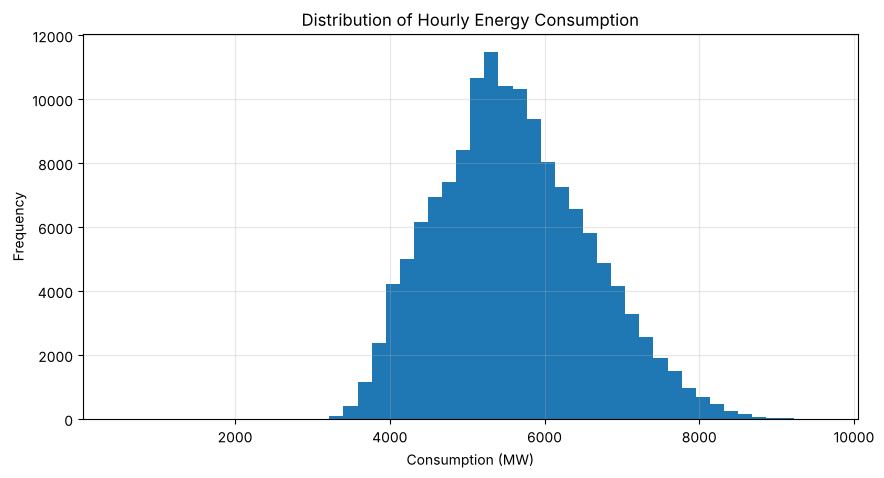

In [17]:
# Visualize the overall distribution of hourly consumption.
# The histogram helps us understand the concentration and spread of demand 
# before deciding whether any extreme values need investigation.

plt.figure(figsize=(10, 5))
plt.hist(clean["PJMW_MW"], bins=50)
plt.title("Distribution of Hourly Energy Consumption")
plt.xlabel("Consumption (MW)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

### Outlier interpretation

The IQR method is used as a **screening technique**, not as an automatic deletion rule. Electricity demand naturally varies with hour, weekday and season, so high or low values can be legitimate demand observations.

The isolated **487 MW** reading at **2003-05-29 00:00** is investigated separately because it is far below the surrounding demand pattern.


## 6. Investigate and correct the isolated local anomaly


### Identify the local reference value


In [18]:
# Investigate the isolated 487 MW observation using comparable observations at the same hour within a local ±7-day window.
# A local same-hour median is used as a robust reference because electricity demand has strong hourly and weekly patterns.

anomaly_time = pd.Timestamp("2003-05-29 00:00:00")
same_hour_window = clean[(clean["Datetime"].dt.hour == anomaly_time.hour) & 
    (clean["Datetime"] >= anomaly_time - pd.Timedelta(days=7)) & 
    (clean["Datetime"] <= anomaly_time + pd.Timedelta(days=7)) & 
    (clean["Datetime"] != anomaly_time)]

original_value = clean.loc[clean["Datetime"] == anomaly_time, "PJMW_MW"].iloc[0]
replacement_value = int(round(same_hour_window["PJMW_MW"].median()))

print("Original value:", original_value, "MW")
print("Same-hour ±7-day median:", replacement_value, "MW")

Original value: 487.0 MW
Same-hour ±7-day median: 4786 MW


### Replace the isolated anomaly


In [19]:
# Replace only the specifically investigated local anomaly with the robust same-hour reference value.
# No other IQR-flagged observations are automatically removed or modified.

clean.loc[clean["Datetime"] == anomaly_time, "PJMW_MW"] = replacement_value
print("Corrected value:", clean.loc[clean["Datetime"] == anomaly_time, "PJMW_MW"].iloc[0], "MW")

Corrected value: 4786.0 MW


### Check the surrounding observations


In [20]:
# Inspect the observations immediately around the corrected timestamp.
# This provides a simple before/after context check to confirm that the replacement is locally reasonable.

nearby = clean[(clean["Datetime"] >= anomaly_time - pd.Timedelta(hours=2)) & 
    (clean["Datetime"] <= anomaly_time + pd.Timedelta(hours=2))]
print(nearby)

                 Datetime  PJMW_MW
10146 2003-05-28 22:00:00   5746.0
10147 2003-05-28 23:00:00   5317.0
10148 2003-05-29 00:00:00   4786.0
10149 2003-05-29 01:00:00   4560.0
10150 2003-05-29 02:00:00   4424.0


### Method note

The replacement uses the median of the **same hour of day within a ±7-day local window**. This preserves the hourly pattern while reducing the influence of unusually high or low neighboring observations.


## 7. Final cleaned-base validation


### Validate the cleaned dataset


In [21]:
# Final validation of the cleaned base dataset before creating EDA features.
# Confirm row count, missing values, and timestamp uniqueness after all data-quality repairs.

print("Cleaned-base shape:", clean.shape)
print("\nMissing values:")
print(clean.isna().sum())
print("\nDuplicate timestamps:", clean["Datetime"].duplicated().sum())

Cleaned-base shape: (143203, 2)

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate timestamps: 0


### Check date range and remaining time transitions


In [22]:
# Recheck the time range and count the remaining 2-hour transitions.
# Recurring clock-change transitions are expected to remain because they are a property of the source timestamp representation.

clean_diff = clean["Datetime"].diff()
print("Date range:", clean["Datetime"].min(), "to", clean["Datetime"].max())
print("Remaining 2-hour transitions:", (clean_diff == pd.Timedelta(hours=2)).sum())

Date range: 2002-04-01 01:00:00 to 2018-08-03 00:00:00
Remaining 2-hour transitions: 29


### Cleaned base dataset preview


In [23]:
# Preview the cleaned base dataset after validation.

clean.head()

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374.0
1,2002-04-01 02:00:00,4306.0
2,2002-04-01 03:00:00,4322.0
3,2002-04-01 04:00:00,4359.0
4,2002-04-01 05:00:00,4436.0


### Validation result

The cleaned base dataset contains **143,203 rows**, has no missing target values, and has unique timestamps. The recurring clock-change transitions are retained as a property of the source time representation rather than being incorrectly treated as missing observations.


## 8. Create basic time features for EDA


### Extract calendar/time features


In [24]:
# Create a separate EDA copy so the cleaned base dataset remains unchanged.
# Extract calendar/time attributes needed to analyze hourly, weekly, seasonal, and long-term patterns.

eda = clean.copy()
eda["Year"] = eda["Datetime"].dt.year
eda["Month"] = eda["Datetime"].dt.month
eda["Day"] = eda["Datetime"].dt.day
eda["Hour"] = eda["Datetime"].dt.hour
eda["DayOfWeek"] = eda["Datetime"].dt.dayofweek
eda["Is_Weekend"] = (eda["DayOfWeek"] >= 5).astype(int)

### Time-feature preview


In [25]:
# Preview the engineered EDA features and verify that the new calendar columns were created correctly.

eda.head()

,Datetime,PJMW_MW,Year,Month,Day,Hour,DayOfWeek,Is_Weekend
0,2002-04-01 01:00:00,4374.0,2002,4,1,1,0,0
1,2002-04-01 02:00:00,4306.0,2002,4,1,2,0,0
2,2002-04-01 03:00:00,4322.0,2002,4,1,3,0,0
3,2002-04-01 04:00:00,4359.0,2002,4,1,4,0,0
4,2002-04-01 05:00:00,4436.0,2002,4,1,5,0,0


These are **basic calendar features for EDA**. Lag, rolling and other model-specific features will be created later during Model Building after the time-based split.


## 9. Overall time-series trend


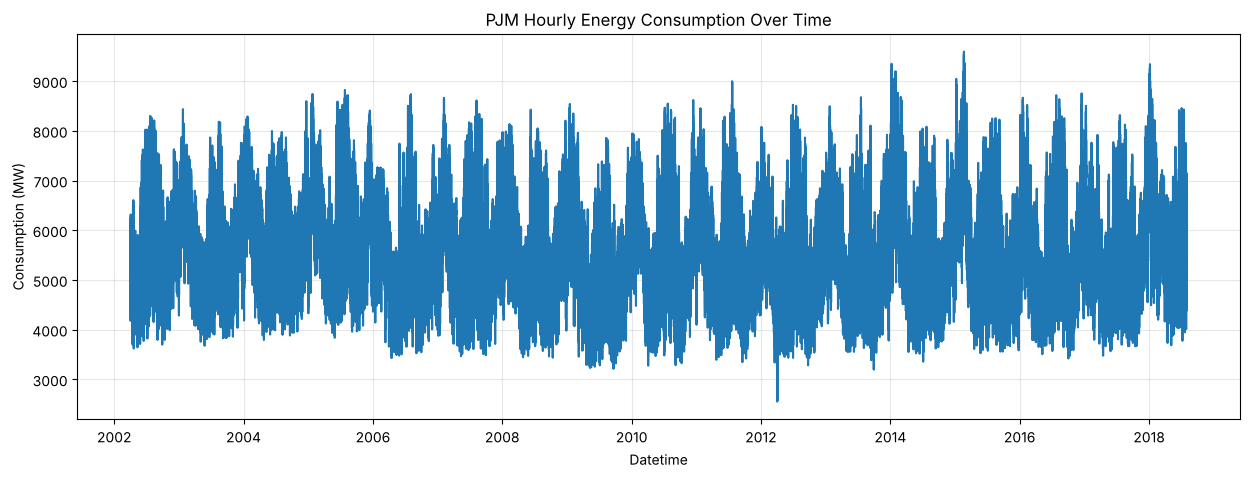

In [26]:
# Plot the complete cleaned time series to understand long-term variation and changes in consumption over time.

plt.figure(figsize=(15, 5))
plt.plot(eda["Datetime"], eda["PJMW_MW"])
plt.title("PJM Hourly Energy Consumption Over Time")
plt.xlabel("Datetime")
plt.ylabel("Consumption (MW)")
plt.grid(True, alpha=0.3)
plt.show()

### Key observation

The series shows substantial variation over time, supporting the need for time-based features and a chronological validation strategy rather than a random train/test split.


## 10. Average consumption by hour of day


### Calculate hourly averages


In [27]:
# Calculate the mean electricity consumption for each hour of the day.
# This reveals the typical intraday demand pattern across the full dataset.

hourly_avg = eda.groupby("Hour")["PJMW_MW"].mean()
print(hourly_avg)

Hour
0     5231.322554
1     4940.489276
2     4779.577233
3     4697.121996
4     4672.537366
5     4734.933479
6     4958.209450
7     5323.434316
8     5571.168398
9     5708.667058
10    5818.219169
11    5904.120476
12    5947.523794
13    5959.946716
14    5970.935824
15    5953.164712
16    5957.636394
17    6031.231233
18    6158.806803
19    6199.285355
20    6183.568365
21    6152.210121
22    5982.300436
23    5618.226206
Name: PJMW_MW, dtype: float64


### Visualize hourly pattern


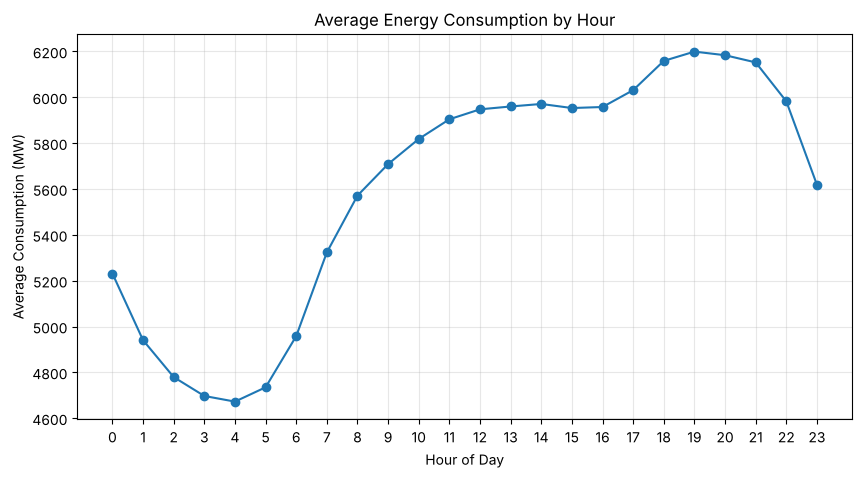

In [28]:
# Visualize the average consumption profile across all 24 hours.
# This makes peak and low-demand periods easier to identify than the printed table alone.

plt.figure(figsize=(10, 5))
plt.plot(hourly_avg.index, hourly_avg.values, marker="o")
plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

### Highest and lowest average hours


In [29]:
# Identify the hours with the highest and lowest average consumption.
# These are descriptive EDA results, not forecasts.

print("Highest average hour:", hourly_avg.idxmax())
print("Lowest average hour:", hourly_avg.idxmin())

Highest average hour: 19
Lowest average hour: 4


## 11. Average consumption by day of week


### Calculate day-of-week averages

In [30]:
# Calculate average consumption for each day of the week.
# DayOfWeek uses 0=Monday through 6=Sunday, so the labels are mapped to readable day names.

dow_avg = eda.groupby("DayOfWeek")["PJMW_MW"].mean()
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_avg.index = [day_names[i] for i in dow_avg.index]
print(dow_avg)

Monday       5700.518783
Tuesday      5801.076837
Wednesday    5802.370701
Thursday     5781.051045
Friday       5686.885129
Saturday     5293.999413
Sunday       5149.834811
Name: PJMW_MW, dtype: float64


### Visualize day-of-week pattern


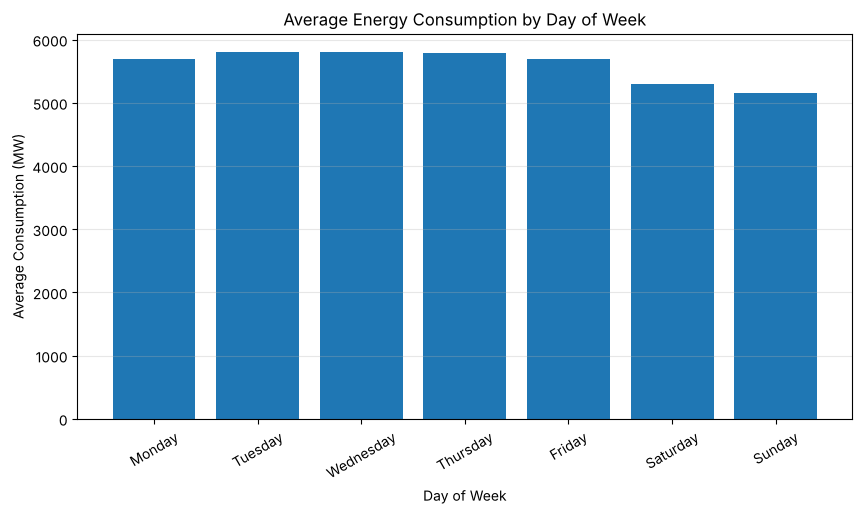

In [31]:
# Visualize the average consumption for each individual day of the week.
# This helps identify weekly differences in demand.

plt.figure(figsize=(10, 5))
plt.bar(dow_avg.index, dow_avg.values)
plt.title("Average Energy Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Consumption (MW)")
plt.xticks(rotation=30)
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 12. Monthly / seasonal pattern


### Calculate monthly averages


In [32]:
# Calculate the average consumption for each calendar month.
# This provides a high-level view of seasonal/monthly demand differences.

monthly_avg = eda.groupby("Month")["PJMW_MW"].mean()
print(monthly_avg)

Month
1     6447.667759
2     6296.808813
3     5654.097376
4     5022.310855
5     5016.185642
6     5516.756046
7     5861.537081
8     5822.142809
9     5205.872049
10    4997.642155
11    5404.067141
12    6064.478411
Name: PJMW_MW, dtype: float64


### Visualize monthly pattern


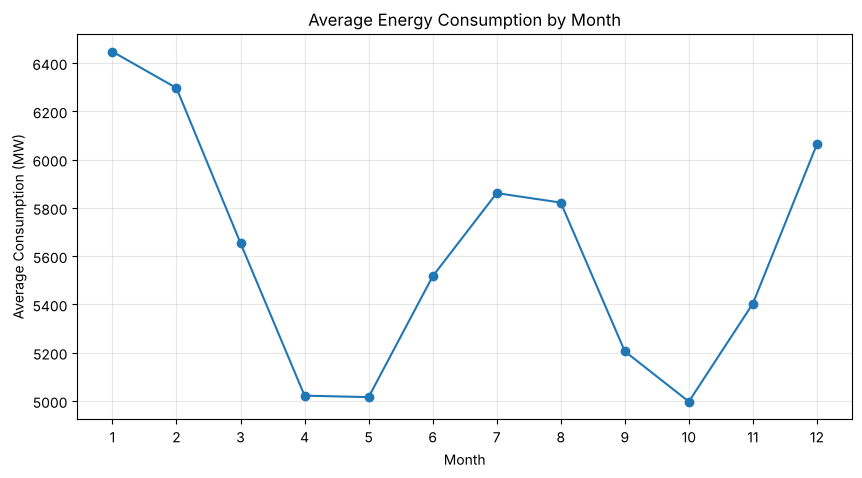

In [33]:
# Visualize monthly average consumption to make the seasonal pattern easier to compare.

plt.figure(figsize=(10, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o")
plt.title("Average Energy Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Consumption (MW)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

## 13. Long-term yearly trend


### Calculate yearly averages


In [34]:
# Calculate the average consumption associated with each year in the dataset.
# This is used to inspect long-term changes rather than individual hourly fluctuations.

yearly_avg = eda.groupby("Year")["PJMW_MW"].mean()
print(yearly_avg)

Year
2002    5621.663180
2003    5701.119091
2004    5866.616602
2005    6038.406029
2006    5425.448847
2007    5635.396780
2008    5530.132544
2009    5290.557433
2010    5573.145581
2011    5509.640215
2012    5395.010818
2013    5556.783626
2014    5656.455646
2015    5621.184439
2016    5578.097632
2017    5500.354150
2018    5848.157516
Name: PJMW_MW, dtype: float64


### Visualize yearly pattern


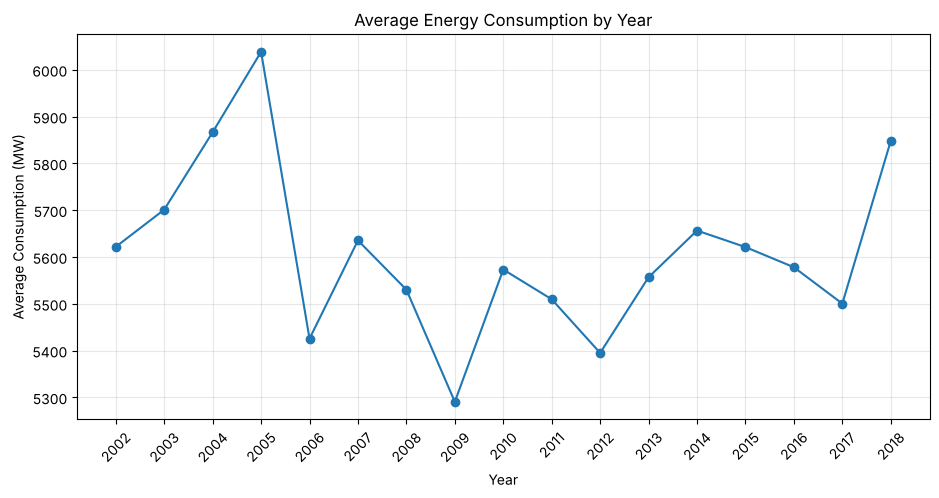

In [35]:
# Visualize the year-wise average consumption to identify broad long-term trends.

plt.figure(figsize=(11, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker="o")
plt.title("Average Energy Consumption by Year")
plt.xlabel("Year")
plt.ylabel("Average Consumption (MW)")
plt.xticks(yearly_avg.index, rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

## 14. Weekend v/s Weekday trend


In [36]:
# Aggregate the data into two groups: weekdays and weekends.
# This complements the day-of-week analysis with a simpler high-level comparison.

weekend_avg = eda.groupby("Is_Weekend")["PJMW_MW"].mean()

weekend_avg.index = ["Weekday", "Weekend"]

weekend_avg

Weekday    5754.396195
Weekend    5221.968263
Name: PJMW_MW, dtype: float64

### Visualize Weekend v/s Weekday Pattern

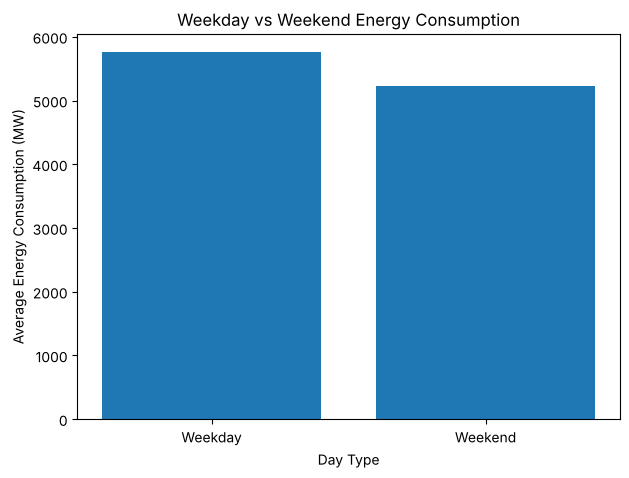

In [37]:
# Visualize the average consumption difference between weekdays and weekends.

plt.figure(figsize=(7, 5))

plt.bar(weekend_avg.index, weekend_avg.values)

plt.title("Weekday vs Weekend Energy Consumption")
plt.xlabel("Day Type")
plt.ylabel("Average Energy Consumption (MW)")

plt.show()

## 15. Summer v/s Winter Trend

In [38]:
# Define simple seasonal groups for EDA.
# Summer is treated as June-August and winter as December-February; the remaining months are kept as 'Other'.
# These labels are used only for comparative EDA and can be refined later if the business/geographic definition requires it.

eda["Season"] = np.select(
    [
        eda["Month"].isin([6, 7, 8]),
        eda["Month"].isin([12, 1, 2])
    ],
    [
        "Summer",
        "Winter"
    ],
    default="Other"
)

season_avg = eda[eda["Season"].isin(["Summer", "Winter"])].groupby(
    "Season"
)["PJMW_MW"].mean()

season_avg

Season
Summer    5734.206129
Winter    6268.824157
Name: PJMW_MW, dtype: float64

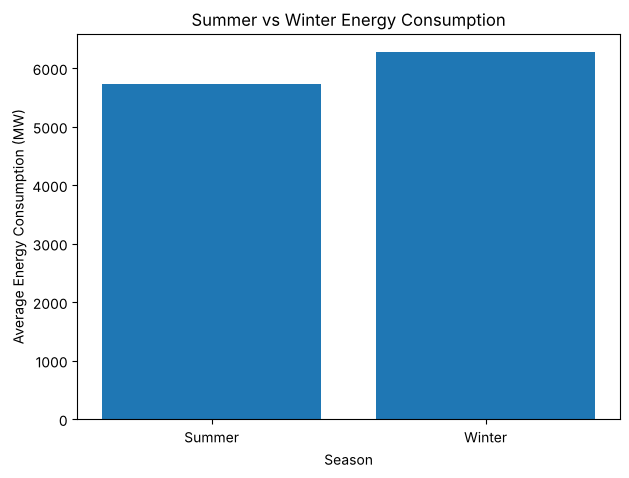

In [39]:
# Compare the overall average consumption of the Summer and Winter groups.

plt.figure(figsize=(7, 5))

plt.bar(season_avg.index, season_avg.values)

plt.title("Summer vs Winter Energy Consumption")
plt.xlabel("Season")
plt.ylabel("Average Energy Consumption (MW)")

plt.show()

## 16. Hourly Pattern: Summer vs Winter

In [40]:
# Calculate hourly consumption profiles separately for Summer and Winter.
# This directly checks whether the intraday demand pattern changes with season.

summer_hourly = (
    eda[eda["Season"] == "Summer"]
    .groupby("Hour")["PJMW_MW"]
    .mean()
)

winter_hourly = (
    eda[eda["Season"] == "Winter"]
    .groupby("Hour")["PJMW_MW"]
    .mean()
)

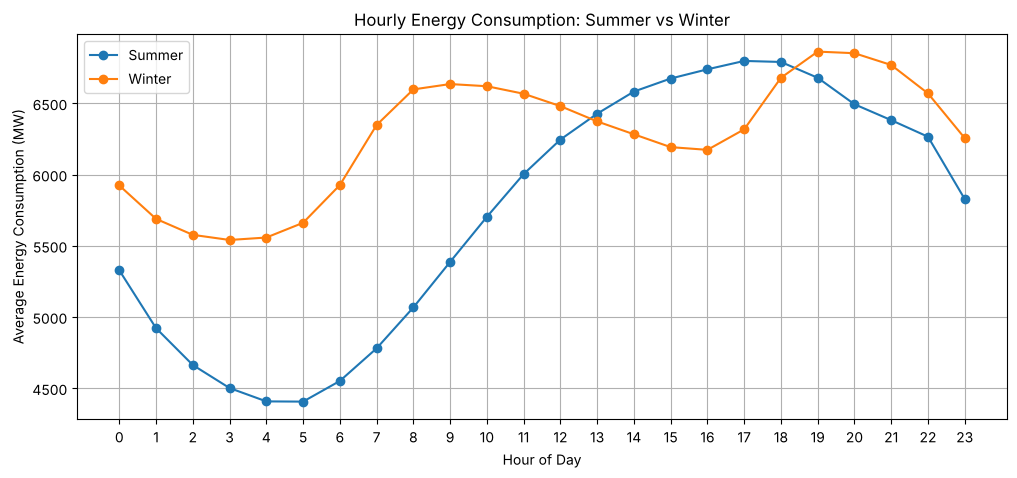

In [41]:
# Plot the Summer and Winter hourly profiles together so differences in daily shape and peak periods are easy to compare.

plt.figure(figsize=(12, 5))

plt.plot(
    summer_hourly.index,
    summer_hourly.values,
    marker="o",
    label="Summer"
)

plt.plot(
    winter_hourly.index,
    winter_hourly.values,
    marker="o",
    label="Winter"
)

plt.title("Hourly Energy Consumption: Summer vs Winter")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumption (MW)")

plt.xticks(range(24))
plt.legend()
plt.grid()

plt.show()

## 17. Month × Hour consumption pattern

In [42]:
# Create a Month × Hour matrix of average consumption.
# This combines monthly and hourly information and helps identify how intraday demand changes across the year.

hour_month = eda.pivot_table(
    values="PJMW_MW",
    index="Month",
    columns="Hour",
    aggfunc="mean"
)

hour_month

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Month,,,,,,,,,,,,,,,,,,,,,
1,6066.701613,5846.125000,5744.000000,5714.372984,5733.824597,5836.754032,6105.453629,6522.723790,6790.247984,6821.002016,...,6485.151210,6389.147177,6369.600806,6506.760081,6883.614919,7046.054435,7018.899194,6925.897177,6716.556452,6401.252016
2,5965.500000,5756.856195,5664.373894,5639.356195,5665.035398,5774.393805,6051.477876,6493.586283,6708.566372,6725.325221,...,6292.141593,6190.223451,6150.840708,6235.396018,6471.378319,6792.044248,6821.787611,6742.006637,6544.628319,6244.477876
3,5325.233871,5117.151210,5021.641129,5001.956612,5020.395161,5134.528226,5419.360887,5868.661290,6089.157258,6103.687500,...,5737.939516,5632.358871,5570.792339,5594.094758,5674.989919,5856.645161,6047.854839,6096.000000,5916.258065,5606.622984
4,4690.776031,4447.550980,4324.039216,4276.259406,4283.160784,4371.398039,4631.650980,5051.403922,5265.805882,5341.901961,...,5269.768627,5202.666667,5160.380392,5167.260784,5185.511765,5203.811765,5295.374510,5515.935294,5379.007843,5035.445098
5,4662.529412,4348.996205,4178.210626,4083.990512,4051.110057,4100.130930,4311.036053,4634.654649,4897.901328,5067.546490,...,5491.867173,5494.290323,5503.586338,5538.398482,5544.203036,5500.850095,5456.024668,5541.563567,5487.218216,5099.248577
6,5133.729412,4737.149020,4493.323529,4346.854902,4266.764706,4276.674510,4427.547059,4661.156863,4985.056863,5287.047059,...,6274.719608,6342.835294,6398.394118,6454.443137,6450.915686,6358.711765,6203.633333,6086.278431,6040.041176,5634.482353
7,5460.648956,5039.225806,4762.104364,4585.269450,4478.612903,4465.341556,4594.208729,4782.825427,5089.514231,5444.434535,...,6779.366224,6874.796964,6939.478178,6996.806452,6989.309298,6876.929791,6675.565465,6503.290323,6406.195446,5975.654649
8,5385.723447,4985.383534,4730.937751,4569.746988,4475.813253,4474.913655,4630.726908,4897.935743,5127.329317,5427.566265,...,6689.997992,6801.196787,6875.622490,6938.759036,6928.044177,6798.853414,6597.429719,6556.002008,6347.431727,5868.495984
9,4778.172917,4460.281250,4270.660417,4159.691667,4103.233333,4131.070833,4327.906250,4718.191667,4909.970833,5085.262500,...,5810.979167,5864.664583,5908.420833,5960.756250,5955.045833,5868.018750,5895.647917,5909.270833,5605.489583,5180.208333


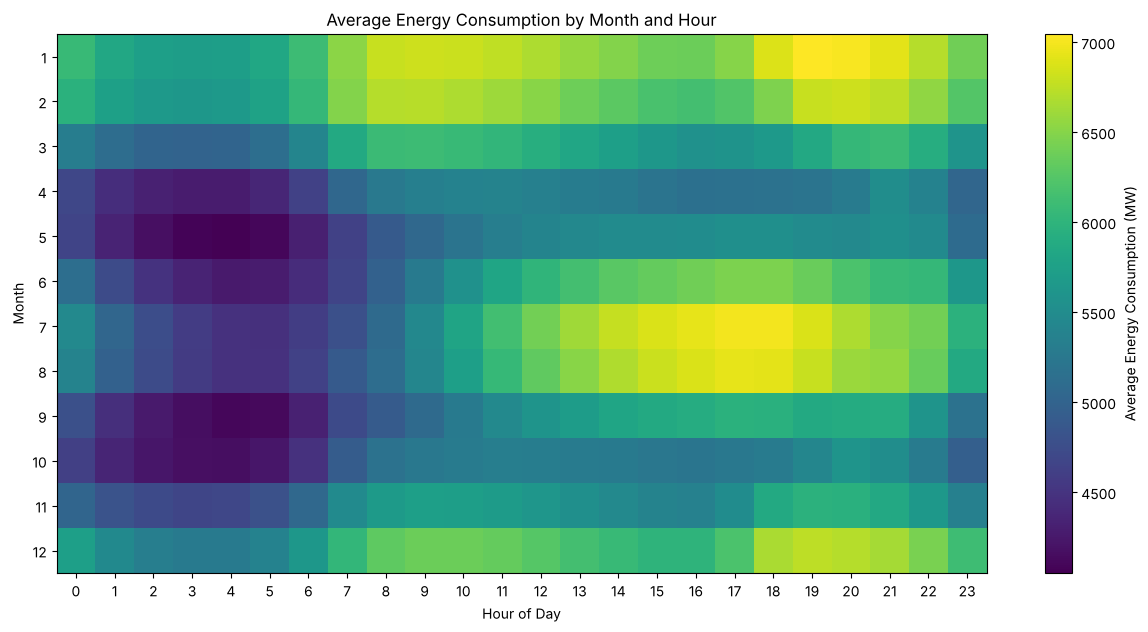

In [43]:
# Visualize the Month × Hour matrix as a heatmap.
# Darker/lighter regions represent higher/lower average consumption and make seasonal hourly patterns easier to spot.

plt.figure(figsize=(15, 7))

plt.imshow(hour_month, aspect="auto")

plt.colorbar(label="Average Energy Consumption (MW)")

plt.title("Average Energy Consumption by Month and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Month")

plt.xticks(range(24), range(24))
plt.yticks(range(12), range(1, 13))

plt.show()

## 18. Holiday Analysis

In [44]:
# The assessment does not define a holiday calendar
# So a U.S. federal holiday calendar is used as a consistent reference for this analysis.

from pandas.tseries.holiday import USFederalHolidayCalendar

holidays = USFederalHolidayCalendar().holidays(
    start=eda["Datetime"].min(),
    end=eda["Datetime"].max()
)

eda["is_holiday"] = eda["Datetime"].dt.normalize().isin(holidays)

holiday_pattern = eda.groupby("is_holiday")["PJMW_MW"].mean()

print("Average consumption on non-holidays:",
      holiday_pattern.get(False))

print("Average consumption on holidays:",
      holiday_pattern.get(True))

Average consumption on non-holidays: 5604.826493916664
Average consumption on holidays: 5517.403034979424


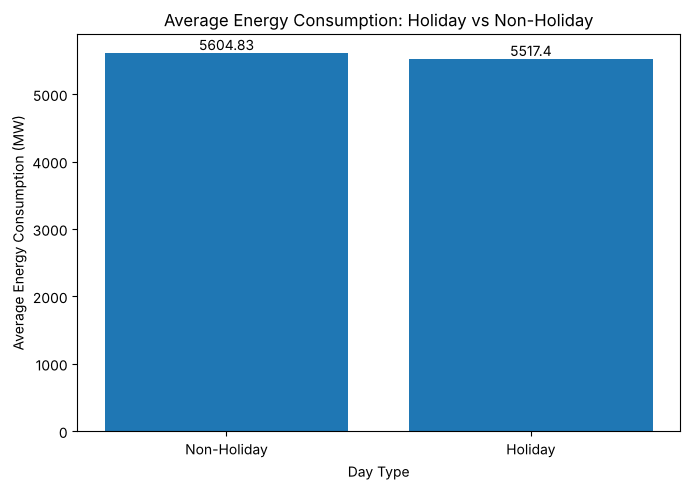

In [45]:
# Visualize average energy consumption on holidays vs non-holidays.
# The values are displayed on the bars for easier interpretation during presentation.

holiday_plot = holiday_pattern.rename(index={False: "Non-Holiday", True: "Holiday"})

plt.figure(figsize=(7, 5))
bars = plt.bar(holiday_plot.index, holiday_plot.values)

plt.title("Average Energy Consumption: Holiday vs Non-Holiday")
plt.xlabel("Day Type")
plt.ylabel("Average Energy Consumption (MW)")

plt.bar_label(bars)
plt.tight_layout()
plt.show()

## 19. Final Week 1 cleaned base dataset validation.

In [46]:

# ============================================================
# FINAL DATASET PREPARATION FOR MODEL BUILDING
# ============================================================

# Copy EDA data to preserve the cleaned dataset and existing features
Final_data = eda.copy()

# Ensure chronological order
Final_data = Final_data.sort_values("Datetime").reset_index(drop=True)

# Create essential time-based features
Final_data["Year"] = Final_data["Datetime"].dt.year
Final_data["Month"] = Final_data["Datetime"].dt.month
Final_data["Day"] = Final_data["Datetime"].dt.day
Final_data["Hour"] = Final_data["Datetime"].dt.hour
Final_data["DayOfWeek"] = Final_data["Datetime"].dt.dayofweek

Final_data["Is_Weekend"] = (
    Final_data["DayOfWeek"] >= 5
).astype(int)

# Assign a season to every observation
season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

Final_data["Season"] = Final_data["Month"].map(season_map)

# Lag features
Final_data["Lag_1H"] = Final_data["PJMW_MW"].shift(1)
Final_data["Lag_24H"] = Final_data["PJMW_MW"].shift(24)
Final_data["Lag_48H"] = Final_data["PJMW_MW"].shift(48)
Final_data["Lag_7D"] = Final_data["PJMW_MW"].shift(168)

# Rolling features using past observations only
Final_data["Rolling_Mean_24H"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=24).mean()
)

Final_data["Rolling_Mean_48H"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=48).mean()
)

Final_data["Rolling_Mean_7D"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=168).mean()
)

Final_data["Rolling_Std_24H"] = (
    Final_data["PJMW_MW"].shift(1).rolling(window=24).std()
)

# Remove rows without sufficient historical observations
Final_data = Final_data.dropna().reset_index(drop=True)

# Validate the final dataset
print("Final dataset shape:", Final_data.shape)

print("\nSeason distribution:")
print(Final_data["Season"].value_counts())

print("\nDuplicate timestamps:",
      Final_data["Datetime"].duplicated().sum())

Final dataset shape: (143035, 18)

Season distribution:
Season
Summer    36841
Spring    36606
Autumn    34932
Winter    34656
Name: count, dtype: int64

Duplicate timestamps: 0


## FINAL DATASET

In [47]:
# Display the final dataset
Final_data.head()

,Datetime,PJMW_MW,Year,Month,Day,Hour,DayOfWeek,Is_Weekend,Season,is_holiday,Lag_1H,Lag_24H,Lag_48H,Lag_7D,Rolling_Mean_24H,Rolling_Mean_48H,Rolling_Mean_7D,Rolling_Std_24H
0,2002-04-08 02:00:00,4532.0,2002,4,8,2,0,0,Spring,False,4634.0,5002.0,5082.0,4374.0,5029.625000,5193.708333,5379.339286,234.430264
1,2002-04-08 03:00:00,4481.0,2002,4,8,3,0,0,Spring,False,4532.0,4858.0,4992.0,4306.0,5010.041667,5182.250000,5380.279762,255.520522
2,2002-04-08 04:00:00,4527.0,2002,4,8,4,0,0,Spring,False,4481.0,4871.0,4932.0,4322.0,4994.333333,5171.604167,5381.321429,276.038225
3,2002-04-08 05:00:00,4640.0,2002,4,8,5,0,0,Spring,False,4527.0,4909.0,4956.0,4359.0,4980.000000,5163.166667,5382.541667,291.233658
4,2002-04-08 06:00:00,4940.0,2002,4,8,6,0,0,Spring,False,4640.0,5038.0,4997.0,4436.0,4968.791667,5156.583333,5384.214286,299.153586


## Lag Features

Lag features contain previous electricity consumption values. They help the model learn from historical demand.

- **Lag_1H:** Electricity consumption one hour before the current timestamp. Helps capture short-term changes and hourly continuity.
- **Lag_24H:** Electricity consumption at the same hour on the previous day, 24 hours earlier. Helps capture daily repeating patterns.
- **Lag_48H:** Electricity consumption at the same hour on the previous day, 48 hours earlier. Helps capture daily repeating patterns.
- **Lag_7D:** Electricity consumption at the same hour on the previous week, 168 hours earlier (24 × 7). Helps capture weekly repeating patterns.

## Rolling Features

Rolling features summarize recent historical consumption over a fixed time window. They help the model understand the recent demand level and how much it varies.

- **Rolling_Mean_24H:** The average electricity consumption over the previous 24 hours, excluding the current timestamp. Helps represent the recent daily demand level.
- **Rolling_Mean_48H:** The average electricity consumption over the previous 48 hours, excluding the current timestamp. Helps represent the recent weekly demand level.
- **Rolling_Mean_7D:** The average electricity consumption over the previous 168 hours (7 days), excluding the current timestamp. Helps represent the recent weekly demand level.
- **Rolling_Std_24H:** The standard deviation of consumption over the previous 24 hours, excluding the current timestamp. Helps measure how much electricity demand fluctuated during the previous day.

## 21. Week 1 EDA and Final Dataset Preparation — Conclusion

### Data-quality work completed
- Inspected the raw dataset for shape, data types, missing values, duplicates, and date range.
- Sorted the data chronologically and investigated timestamp gaps.
- Consolidated duplicate timestamps using the mean because timezone/DST information was unavailable.
- Estimated the missing observation at **2010-12-10 00:00** using the mean of its immediately adjacent hourly observations.
- Investigated the isolated **487 MW** observation at **2003-05-29 00:00** and replaced it with a same-hour local median estimate.
- Validated the cleaned base dataset for missing values and duplicate timestamps.

### EDA completed
- Overall time-series trend and long-term yearly pattern.
- Hour-of-day and day-of-week patterns.
- Weekday versus weekend comparison.
- Monthly and seasonal consumption patterns.
- Summer versus winter comparison and hourly seasonal profiles.
- Month × Hour heatmap.
- Holiday versus non-holiday comparison using the U.S. Federal Holiday Calendar as an external reference.

### Holiday analysis assumption
- The original dataset does not include a holiday indicator.
- A U.S. Federal Holiday Calendar was used as a consistent reference for exploratory analysis.
- Average consumption was compared between observations classified as holidays and non-holidays.
- The results describe differences under the selected calendar definition and do not establish that holidays directly cause changes in consumption.

### Final dataset preparation
- Created **`Final_data`** as a copy of the EDA dataset, preserving the cleaned consumption data and existing EDA features.
- Ensured chronological ordering and prepared time-based features: `Year`, `Month`, `Day`, `Hour`, `DayOfWeek`, `Is_Weekend`, and `Season`.
- Added lag features: `Lag_1H`, `Lag_24H`, `Lag_48H`and `Lag_7D`, representing consumption one hour, one day, and one week earlier.
- Added rolling features: `Rolling_Mean_24H`, `Rolling_Mean_48H`, `Rolling_Mean_7D`, and `Rolling_Std_24H`, summarizing recent consumption levels and variability using past observations only.
- Removed initial rows without sufficient historical observations for the lag and rolling calculations.
- Preserved the holiday indicator if it was already present in the EDA dataset; any separately stored holiday information must be merged before modeling.
- The resulting `Final_data` is the **feature-engineered dataset prepared for the modeling stage**, not the completed model-training pipeline.


# Week 2 — Hourly Time-Series Model Building, Evaluation and Deployment

## Objective and modeling protocol

This section uses the existing `Final_data` and target `PJMW_MW`. **Cells 0–117 (EDA and final dataset preparation) are intentionally preserved unchanged.** The modeling code works on a separate copy and does not rewrite `Final_data`.

The target is **hourly PJM West consumption in MW**. The business question is a **30-day (720-hour) forecast**, with the **last year held out as the test set**.

**Chronological design**
- **Test set:** the final 365 days (never used for tuning or selection).
- **Validation set:** the 365 days immediately before the test year, scored as **twelve consecutive 30-day forecast windows** (one full seasonal cycle). All model/configuration choices are made on validation only.
- **Training data:** everything before the forecast origin. At every origin the models are refitted using only data that was known at that time.
- **Test protocol:** rolling-origin evaluation. The test year is forecast in consecutive 30-day blocks; after a block is finished its actuals become known history for the next block (exactly how a monthly forecasting service would run).

**Model families compared:** ARIMA, SARIMA, Decision Tree, XGBoost and LightGBM, plus a simple average of the two boosted models, and a *weekly seasonal-naive* benchmark ("same hour last week").

**Metrics:** MAE and RMSE (in MW) are the primary measures — **lower is better**; sMAPE/MAPE give percentage context, MASE compares the error with a seasonal-naive scale, and R² is supplementary (not an accuracy percentage).

**Key modeling decision (improvement over the earlier recursive version).** A 30-day forecast cannot use *actual* recent demand beyond the first hour. A *recursive* model feeds its own predictions back as lags, so its errors compound and it drifts toward a flat average. Here every future hour is predicted **directly** from (a) calendar and holiday features that are known in advance and (b) values anchored to the **last observed hour** — e.g. "same hour last week", "same hour last year", recent demand level. This removes error build-up, is faster, and is the same logic the Streamlit app uses.

In [48]:
# Imports for time-series modeling, diagnostics, metrics, plots and reproducible artifacts.
import os, json, time, warnings, joblib, calendar
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pandas.tseries.holiday import USFederalHolidayCalendar
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
N_JOBS = max(1, min(4, os.cpu_count() or 1))
print('Modeling libraries imported successfully.')

Modeling libraries imported successfully.


## 0. Build the hourly modeling series

`resample('h')` places the data on a strict hourly grid (if an hour has no observation, pandas creates that hour with `NaN`). Only isolated gaps of up to 2 hours are repaired by time interpolation — interpolation *estimates* a value, it does not recover the real recorded consumption. Any longer gap would raise an error so that it is investigated rather than silently filled.

In [49]:
# Create an hourly target series from Final_data without modifying Final_data itself.
required_columns = {'Datetime', 'PJMW_MW'}
missing_columns = required_columns.difference(Final_data.columns)
if missing_columns:
    raise KeyError(f'Final_data is missing required columns: {sorted(missing_columns)}')

model_data = Final_data[['Datetime', 'PJMW_MW']].copy()
model_data['Datetime'] = pd.to_datetime(model_data['Datetime'], errors='coerce')
model_data['PJMW_MW'] = pd.to_numeric(model_data['PJMW_MW'], errors='coerce')
model_data = model_data.dropna(subset=['Datetime', 'PJMW_MW']).sort_values('Datetime')
model_data = model_data.drop_duplicates('Datetime', keep='last').set_index('Datetime')['PJMW_MW']
model_data = model_data.resample('h').mean()

# Repair only isolated/short timestamp gaps in this modeling copy. A long gap is flagged for review.
missing_before = int(model_data.isna().sum())
model_data = model_data.interpolate(method='time', limit=2, limit_area='inside')
if model_data.isna().any():
    raise ValueError('Unresolved missing hourly target values remain after limited interpolation; inspect the data before modeling.')
if not model_data.index.is_monotonic_increasing or model_data.index.has_duplicates:
    raise ValueError('Modeling index must be chronological and unique.')

print(f'Hourly observations: {len(model_data):,}')
print(f'Date range: {model_data.index.min()} to {model_data.index.max()}')
print(f'Missing hourly values before limited interpolation: {missing_before}')
print(f'Missing hourly values after preparation: {int(model_data.isna().sum())}')
print(f'Median hourly consumption: {model_data.median():,.2f} MW')

Hourly observations: 143,063
Date range: 2002-04-08 02:00:00 to 2018-08-03 00:00:00
Missing hourly values before limited interpolation: 28
Missing hourly values after preparation: 0
Median hourly consumption: 5,530.00 MW


## 1. Chronological train, validation and test design

The last 365 days are held out for final testing. The 365 days before them are the validation year, divided into **twelve non-overlapping 30-day forecast windows** so that every season is represented when models are compared. Earlier observations are training data.

- **Validation:** 12 windows × 720 h = 8,640 forecast hours (the last 120 hours of the validation year do not fill a full window and are not scored).
- **Test:** 13 rolling 30-day blocks cover all 8,760 hours of the held-out year (the 13th block is a short 120-hour block).
- The statistical models (ARIMA/SARIMA) are estimated on a trailing 14-day window, as is standard for hourly SARIMA, to keep estimation tractable. The machine-learning models learn from the whole history before each forecast origin.

In [50]:
HOURS_PER_DAY = 24                           # One day contains 24 hourly observations.
VALIDATION_HOURS = 365 * HOURS_PER_DAY       # One year of validation data.
TEST_HOURS = 365 * HOURS_PER_DAY             # One year of test data.
HORIZON = 30 * HOURS_PER_DAY                 # A 30-day forecasting window = 720 hours.
if len(model_data) <= TEST_HOURS + VALIDATION_HOURS + 3 * 365 * HOURS_PER_DAY:
    raise ValueError('Not enough observations for the defined chronological split and feature windows.')

test_start_pos = len(model_data) - TEST_HOURS
validation_start_pos = test_start_pos - VALIDATION_HOURS
validation_start = model_data.index[validation_start_pos]
test_start = model_data.index[test_start_pos]
train_series = model_data.iloc[:validation_start_pos].copy()                # all observations before validation
validation_series = model_data.iloc[validation_start_pos:test_start_pos].copy()  # used to compare / select models
test_series = model_data.iloc[test_start_pos:].copy()                       # untouched final year

split_summary = pd.DataFrame([
    {'Split': 'Training',      'Start': train_series.index.min(),      'End': train_series.index.max(),      'Observations': len(train_series)},
    {'Split': 'Validation',    'Start': validation_series.index.min(), 'End': validation_series.index.max(), 'Observations': len(validation_series)},
    {'Split': 'Held-out test', 'Start': test_series.index.min(),       'End': test_series.index.max(),       'Observations': len(test_series)},
])
display(split_summary)

VALIDATION_WINDOWS = [validation_series.index[i:i + HORIZON] for i in range(0, len(validation_series), HORIZON)
                      if len(validation_series.index[i:i + HORIZON]) == HORIZON]
TEST_BLOCKS = [test_series.index[i:i + HORIZON] for i in range(0, len(test_series), HORIZON)]
assert len(VALIDATION_WINDOWS) == 12 and all(len(w) == HORIZON for w in VALIDATION_WINDOWS)
print(f'Validation protocol: {len(VALIDATION_WINDOWS)} consecutive {HORIZON}-hour forecast windows (one per ~month of the validation year).')
print(f'Test protocol: {len(TEST_BLOCKS)} rolling 30-day blocks covering all {len(test_series):,} held-out hours.')

,Split,Start,End,Observations
0,Training,2002-04-08 02:00:00,2016-08-03,125543
1,Validation,2016-08-03 01:00:00,2017-08-03,8760
2,Held-out test,2017-08-03 01:00:00,2018-08-03,8760


Validation protocol: 12 consecutive 720-hour forecast windows (one per ~month of the validation year).
Test protocol: 13 rolling 30-day blocks covering all 8,760 held-out hours.


**Why several windows?** One 30-day window can be unusually easy or hard (a heat wave, a mild winter). Averaging across twelve windows shows whether a model is consistently good through the whole seasonal cycle. Validation results choose the model and its settings; the test year only reports how the chosen model generalises.

## 2. Stationarity and seasonal diagnostics

The Augmented Dickey–Fuller (ADF) test is run on a recent slice of the training series and on its first difference. The autocorrelation at lags 24 h and 168 h shows how strongly demand repeats daily and weekly. These diagnostics guide the model specification; they do not replace out-of-sample validation.

- *Stationary* data have a stable mean, variance and autocorrelation over time. *Seasonal* data repeat at regular intervals (daily, weekly, yearly).
- `autolag='AIC'` lets the Akaike Information Criterion choose the number of lags automatically — it balances goodness of fit against model complexity.
- ADF p-value < 0.05 → evidence that the series is stationary; p-value ≥ 0.05 → insufficient evidence.

In [51]:
# Use a recent training sample for diagnostics so the validation and test periods remain untouched.
adf_sample = train_series.tail(180 * HOURS_PER_DAY)          # most recent 180 days of training data
adf_level = adfuller(adf_sample, autolag='AIC')               # stationarity of the original consumption values
adf_diff = adfuller(adf_sample.diff().dropna(), autolag='AIC')  # stationarity after first differencing
adf_results = pd.DataFrame([
    {'Series': 'Training level (recent 180 days)', 'ADF statistic': adf_level[0], 'p-value': adf_level[1], 'Lags used': adf_level[2]},
    {'Series': 'First difference',                 'ADF statistic': adf_diff[0],  'p-value': adf_diff[1],  'Lags used': adf_diff[2]},
])
display(adf_results.round(4))

acf_values = acf(train_series.tail(365 * HOURS_PER_DAY), nlags=168, fft=True)
print(f'Autocorrelation at lag 1 h  : {acf_values[1]:.3f}')
print(f'Autocorrelation at lag 24 h : {acf_values[24]:.3f}  (same hour yesterday)')
print(f'Autocorrelation at lag 168 h: {acf_values[168]:.3f}  (same hour last week)')
display(Markdown(
    f"**Finding.** The ADF p-value of {adf_level[1]:.4f} on the recent level series "
    f"{'indicates the series is stationary around its seasonal pattern' if adf_level[1] < 0.05 else 'does not reject a unit root'}, "
    f"and differencing gives p = {adf_diff[1]:.4f}. Demand is strongly self-similar at 24 h ({acf_values[24]:.2f}) and 168 h ({acf_values[168]:.2f}), "
    "which confirms the daily and weekly cycles seen in the EDA — so the models must encode hour-of-day, day-of-week and 'same hour last week' information. "
    "Because the model choice still depends on how well each model forecasts unseen data, selection below is based on validation forecasts."))

,Series,ADF statistic,p-value,Lags used
0,Training level (recent 180 days),-4.4947,0.0002,29
1,First difference,-12.0470,0.0000,28


Autocorrelation at lag 1 h  : 0.977
Autocorrelation at lag 24 h : 0.874  (same hour yesterday)
Autocorrelation at lag 168 h: 0.685  (same hour last week)


**Finding.** The ADF p-value of 0.0002 on the recent level series indicates the series is stationary around its seasonal pattern, and differencing gives p = 0.0000. Demand is strongly self-similar at 24 h (0.87) and 168 h (0.68), which confirms the daily and weekly cycles seen in the EDA — so the models must encode hour-of-day, day-of-week and 'same hour last week' information. Because the model choice still depends on how well each model forecasts unseen data, selection below is based on validation forecasts.

## 3. Shared forecasting features and evaluation metrics

**Direct multi-horizon feature design.** Each training example is a pair *(forecast origin, hours ahead)*. For a target hour `t` that lies `k` hours after the last known observation:

| Group | Features | Why |
|---|---|---|
| Calendar (known for any future date) | hour, day of week, day of year, month, weekend flag, sine/cosine of hour / weekday / year | daily, weekly and seasonal cycles |
| Holidays | U.S. federal holiday flag, day-before and day-after flags | the EDA used the same federal holiday calendar |
| Horizon | `steps_ahead` (1–720) | lets the model trust recent information less as the horizon grows |
| Recent level | last observed value, mean of the last 24 h / 168 h / 720 h | current demand regime (weather-driven) |
| Anchored lags | same hour of day (most recent known day), same hour of week, average of the last 4 same-hours-of-week, average of the last 7 same-hours-of-day | repeating daily/weekly shape |
| Yearly memory | same weekday/hour 52 weeks earlier, ±3-day smoothed version, recent level ÷ level a year earlier | seasonal level and year-to-year growth |

All features use data at or **before the forecast origin only**, so there is no leakage, and the same function is used by the Streamlit backend (`model_deployment.py`).

In [52]:
HORIZON_HOURS = 720                  # longest forecast horizon: 30 days x 24 hours
YEAR_LAG = 364 * 24                  # 8,736 h = exactly 52 weeks -> same weekday and hour one year earlier
MIN_ORIGIN_POSITION = YEAR_LAG + HORIZON_HOURS + 200   # earliest usable forecast origin inside the history
US_HOLIDAYS = USFederalHolidayCalendar().holidays(start='2000-01-01', end='2035-12-31')

CALENDAR_FEATURES = [
    'hour', 'day_of_week', 'day_of_year', 'month', 'is_weekend',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'year_sin', 'year_cos',
    'is_holiday', 'is_holiday_eve', 'is_holiday_after',
]
ANCHORED_FEATURES = [
    'steps_ahead', 'last_value', 'mean_24', 'mean_168', 'mean_720',
    'anchor_24', 'anchor_168', 'anchor_168_avg4', 'anchor_24_avg7',
    'last_year_same_hour', 'last_year_smooth', 'growth_720',
]
FEATURES = CALENDAR_FEATURES + ANCHORED_FEATURES


def calendar_features(target_index):
    """Calendar / holiday features of the timestamps being predicted (known in advance for any future date)."""
    target_index = pd.DatetimeIndex(target_index)
    hour, dow, doy = target_index.hour, target_index.dayofweek, target_index.dayofyear
    day = target_index.normalize()
    return pd.DataFrame({
        'hour': hour, 'day_of_week': dow, 'day_of_year': doy, 'month': target_index.month,
        'is_weekend': (dow >= 5).astype(int),
        'hour_sin': np.sin(2*np.pi*hour/24), 'hour_cos': np.cos(2*np.pi*hour/24),
        'dow_sin': np.sin(2*np.pi*dow/7), 'dow_cos': np.cos(2*np.pi*dow/7),
        'year_sin': np.sin(2*np.pi*doy/365.25), 'year_cos': np.cos(2*np.pi*doy/365.25),
        'is_holiday': day.isin(US_HOLIDAYS).astype(int),
        'is_holiday_eve': (day + pd.Timedelta(days=1)).isin(US_HOLIDAYS).astype(int),
        'is_holiday_after': (day - pd.Timedelta(days=1)).isin(US_HOLIDAYS).astype(int),
    }, index=target_index)[CALENDAR_FEATURES]


def anchored_features(values, origin_pos, steps):
    """History-anchored features. `origin_pos` is the position of the LAST KNOWN observation and `steps` is how many
    hours ahead the target is (1..720). Every value used lies at or before the origin, so there is no leakage."""
    p = np.asarray(origin_pos, dtype=int)
    k = np.asarray(steps, dtype=int)
    q = p + k                                            # position of the target hour
    cs = np.concatenate([[0.0], np.cumsum(values)])
    mean_last = lambda n, pos: (cs[pos + 1] - cs[pos + 1 - n]) / n    # mean of the n hours ending at `pos`
    c24 = np.ceil(k / 24).astype(int)                    # whole days needed to reach back before the origin
    c168 = np.ceil(k / 168).astype(int)                  # whole weeks needed to reach back before the origin
    return pd.DataFrame({
        'steps_ahead': k,
        'last_value': values[p],
        'mean_24': mean_last(24, p), 'mean_168': mean_last(168, p), 'mean_720': mean_last(720, p),
        'anchor_24': values[q - 24*c24],                 # same hour of day, most recent known day
        'anchor_168': values[q - 168*c168],              # same hour of week, most recent known week
        'anchor_168_avg4': np.mean([values[q - 168*(c168 + j)] for j in range(4)], axis=0),
        'anchor_24_avg7': np.mean([values[q - 24*(c24 + j)] for j in range(7)], axis=0),
        'last_year_same_hour': values[q - YEAR_LAG],     # same weekday/hour, 52 weeks earlier
        'last_year_smooth': np.mean([values[q - YEAR_LAG + 24*d] for d in range(-3, 4)], axis=0),
        'growth_720': mean_last(720, p) / mean_last(720, p - YEAR_LAG),   # recent level vs the same window a year ago
    })[ANCHORED_FEATURES]


def build_features(values, target_index, origin_pos, steps):
    """Full feature matrix (calendar + history-anchored) in the exact column order used for training."""
    calendar = calendar_features(target_index).reset_index(drop=True)
    anchored = anchored_features(values, origin_pos, steps)
    return pd.concat([calendar, anchored], axis=1)[FEATURES]

In [53]:
# Training set: random (forecast origin, hours-ahead) pairs drawn only from history that is known at the forecast origin.
N_TRAIN_ROWS = 250_000      # sampled training examples (the full set would be ~90 million origin/step pairs)

def make_training_set(values, index, n_rows=N_TRAIN_ROWS, seed=RANDOM_STATE):
    last_pos = len(values) - 1                                   # last observation available at the forecast origin
    rng = np.random.default_rng(seed)
    origin = rng.integers(MIN_ORIGIN_POSITION, last_pos, size=n_rows)
    step = rng.integers(1, HORIZON_HOURS + 1, size=n_rows)
    keep = origin + step <= last_pos                             # the target must also lie inside the known history
    origin, step = origin[keep], step[keep]
    X = build_features(values, index[origin + step], origin, step)
    y = pd.Series(values[origin + step], name='PJMW_MW')
    return X, y

def fit_ml_model(family, config, history):
    """Fit a tabular ML model on everything known before the forecast origin (the end of `history`)."""
    values = history.to_numpy(dtype=float)
    X, y = make_training_set(values, history.index)
    if family == 'XGBoost':
        model = XGBRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, tree_method='hist', **config)
    elif family == 'LightGBM':
        model = LGBMRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1, subsample_freq=1, **config)
    elif family == 'Decision Tree':
        model = DecisionTreeRegressor(random_state=RANDOM_STATE, **config)
    else:
        raise ValueError(family)
    model.fit(X, y)
    model.n_training_rows_ = int(len(X))
    return model

def forecast_ml_block(model, history, target_index):
    """Direct forecast of every hour in target_index from the last observation in `history` (no recursion)."""
    if target_index[0] != history.index[-1] + pd.Timedelta(hours=1):
        raise ValueError('The forecast block must start one hour after the last known observation.')
    values = history.to_numpy(dtype=float)
    steps = np.arange(1, len(target_index) + 1)
    X = build_features(values, target_index, np.full(len(steps), len(values) - 1), steps)
    return np.maximum(0.0, model.predict(X))

def weekly_naive_block(history, target_index):
    """Benchmark: repeat the most recent known week ("same hour last week")."""
    values = history.to_numpy(dtype=float)
    steps = np.arange(1, len(target_index) + 1)
    return values[len(values) - 1 + steps - 168 * np.ceil(steps / 168).astype(int)]

# Statistical models are fitted on a trailing 14-day window.
def forecast_arima(history, horizon, order):
    fit_series = history.tail(14 * HOURS_PER_DAY)
    fitted = ARIMA(fit_series, order=tuple(order), enforce_stationarity=False, enforce_invertibility=False).fit(method_kwargs={'maxiter': 40})
    forecast = np.asarray(fitted.forecast(steps=horizon), dtype=float)
    return np.clip(forecast, 0, 2 * history.max()), fitted

def forecast_sarima(history, horizon, order, seasonal_order):
    fit_series = history.tail(14 * HOURS_PER_DAY)
    fitted = SARIMAX(fit_series, order=tuple(order), seasonal_order=tuple(seasonal_order), trend='c',
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=25, method='lbfgs')
    forecast = np.asarray(fitted.forecast(steps=horizon), dtype=float)
    return np.clip(forecast, 0, 2 * history.max()), fitted    # clip guards against numerically unstable fits

# Model performance metrics: MAE, RMSE, sMAPE, MAPE, R2 and MASE.
def metric_row(actual, predicted, training_history=None):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
    smape = float(np.mean(200 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8)))
    mape = float(np.mean(np.abs((actual - predicted) / (np.abs(actual) + 1e-8))) * 100)
    r2 = float(r2_score(actual, predicted)) if len(actual) > 1 else np.nan
    mase = np.nan
    if training_history is not None and len(training_history) > 168:
        scale = np.mean(np.abs(training_history.values[168:] - training_history.values[:-168]))   # weekly seasonal-naive error
        mase = float(mae / scale) if scale > 0 else np.nan
    return {'MAE (MW)': mae, 'RMSE (MW)': rmse, 'sMAPE (%)': smape, 'MAPE (%)': mape, 'R2': r2, 'MASE': mase}

print(f'Leakage-safe feature count: {len(FEATURES)}')
print('Features:', ', '.join(FEATURES))

Leakage-safe feature count: 26
Features: hour, day_of_week, day_of_year, month, is_weekend, hour_sin, hour_cos, dow_sin, dow_cos, year_sin, year_cos, is_holiday, is_holiday_eve, is_holiday_after, steps_ahead, last_value, mean_24, mean_168, mean_720, anchor_24, anchor_168, anchor_168_avg4, anchor_24_avg7, last_year_same_hour, last_year_smooth, growth_720


## 4. Model candidates and validation-only tuning

A small, documented set of configurations is compared for each model family, scored on all **twelve validation windows** with identical timestamps. The configuration with the lowest mean validation MAE is retained within each family. The test year is **not** used here.

- **ARIMA** — non-seasonal baseline. **SARIMA** — adds a 24-hour seasonal component.
- **Decision Tree** — a single tree on the direct feature set (shallow vs deeper).
- **XGBoost / LightGBM** — gradient-boosted trees on the same features. Loss functions compared: squared error (penalises large misses), absolute error (directly optimises MAE) and Huber (a robust compromise).

In [54]:
CANDIDATES = {
    'ARIMA': [{'order': (2, 1, 2)}, {'order': (1, 1, 1)}],
    'SARIMA': [
        {'order': (1, 0, 0), 'seasonal_order': (1, 0, 0, 24)},
        {'order': (2, 0, 0), 'seasonal_order': (1, 0, 0, 24)},
    ],
    'Decision Tree': [
        {'max_depth': 12, 'min_samples_leaf': 200},
        {'max_depth': 18, 'min_samples_leaf': 100},
    ],
    'XGBoost': [
        {'objective': 'reg:squarederror', 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.07,
         'min_child_weight': 50, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 2.0},
        {'objective': 'reg:absoluteerror', 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.07,
         'min_child_weight': 100, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 2.0},
    ],
    'LightGBM': [
        {'objective': 'regression_l1', 'n_estimators': 200, 'learning_rate': 0.07, 'num_leaves': 63,
         'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8},
        {'objective': 'huber', 'alpha': 400.0, 'n_estimators': 200, 'learning_rate': 0.07, 'num_leaves': 63,
         'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8},
        {'objective': 'regression', 'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31,
         'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.8},
    ],
}
ML_FAMILIES = ['Decision Tree', 'XGBoost', 'LightGBM']

def forecast_family(family, config, history, target_index):
    """Fit `family` on `history` and forecast `target_index`. Returns (prediction array, fitted object)."""
    if family == 'ARIMA':
        return forecast_arima(history, len(target_index), config['order'])
    if family == 'SARIMA':
        return forecast_sarima(history, len(target_index), config['order'], config['seasonal_order'])
    model = fit_ml_model(family, config, history)
    return forecast_ml_block(model, history, target_index), model

validation_actual = np.concatenate([model_data.reindex(w).to_numpy() for w in VALIDATION_WINDOWS])
validation_rows, selected_configs, validation_predictions = [], {}, {}
start_all = time.time()
for family, configs in CANDIDATES.items():
    candidates = []
    for config in configs:
        t0 = time.time()
        window_metrics, window_preds = [], []
        for window in VALIDATION_WINDOWS:
            history = model_data.loc[model_data.index < window[0]]       # only data known at the forecast origin
            pred, _ = forecast_family(family, config, history, window)
            window_preds.append(np.asarray(pred, dtype=float))
            window_metrics.append(metric_row(model_data.reindex(window), pred, history))
        scores = {k: float(np.mean([m[k] for m in window_metrics])) for k in window_metrics[0]}
        row = {'Model': family, 'Configuration': json.dumps(config, sort_keys=True), **scores,
               'Validation windows': len(window_metrics), 'Tuning time (s)': time.time() - t0}
        candidates.append((row, np.concatenate(window_preds)))
        validation_rows.append(row)
    best_row, best_pred = min(candidates, key=lambda c: c[0]['MAE (MW)'])
    selected_configs[family] = json.loads(best_row['Configuration'])
    validation_predictions[family] = best_pred
    print(f"{family}: selected {selected_configs[family]} | validation MAE = {best_row['MAE (MW)']:.2f} MW")

validation_tuning_results = pd.DataFrame(validation_rows).sort_values(['Model', 'MAE (MW)']).reset_index(drop=True)
print(f'Validation tuning completed in {(time.time() - start_all) / 60:.1f} minutes.')
display(validation_tuning_results.drop(columns=['Configuration']).assign(
    Configuration=validation_tuning_results['Configuration'].str.slice(0, 70)).round(3))

ARIMA: selected {'order': [2, 1, 2]} | validation MAE = 763.72 MW


SARIMA: selected {'order': [2, 0, 0], 'seasonal_order': [1, 0, 0, 24]} | validation MAE = 718.89 MW


Decision Tree: selected {'max_depth': 12, 'min_samples_leaf': 200} | validation MAE = 496.83 MW


XGBoost: selected {'colsample_bytree': 0.8, 'learning_rate': 0.07, 'max_depth': 8, 'min_child_weight': 100, 'n_estimators': 200, 'objective': 'reg:absoluteerror', 'reg_lambda': 2.0, 'subsample': 0.8} | validation MAE = 457.09 MW


LightGBM: selected {'colsample_bytree': 0.8, 'learning_rate': 0.07, 'min_child_samples': 100, 'n_estimators': 200, 'num_leaves': 63, 'objective': 'regression_l1', 'subsample': 0.8} | validation MAE = 449.92 MW
Validation tuning completed in 7.7 minutes.


,Model,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,Validation windows,Tuning time (s),Configuration
0,ARIMA,763.724,941.456,13.867,13.467,-0.380,1.554,12,2.073,"{""order"": [2, 1, 2]}"
1,ARIMA,2028.694,2195.158,49.635,34.821,-6.704,4.134,12,0.626,"{""order"": [1, 1, 1]}"
2,Decision Tree,496.825,622.628,8.792,8.712,0.339,1.011,12,56.650,"{""max_depth"": 12, ""min_samples_leaf"": 200}"
3,Decision Tree,509.055,639.369,8.992,8.938,0.304,1.036,12,60.647,"{""max_depth"": 18, ""min_samples_leaf"": 100}"
4,LightGBM,449.925,572.593,7.927,7.833,0.445,0.916,12,67.513,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
5,LightGBM,459.817,579.987,8.092,8.014,0.428,0.936,12,63.309,"{""alpha"": 400.0, ""colsample_bytree"": 0.8, ""lea..."
6,LightGBM,463.598,581.467,8.168,8.117,0.423,0.944,12,66.932,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
7,SARIMA,718.890,886.407,12.920,13.202,-0.208,1.463,12,11.305,"{""order"": [2, 0, 0], ""seasonal_order"": [1, 0, ..."
8,SARIMA,719.455,886.950,12.877,13.563,-0.231,1.465,12,8.920,"{""order"": [1, 0, 0], ""seasonal_order"": [1, 0, ..."
9,XGBoost,457.085,577.649,8.054,7.950,0.431,0.930,12,75.527,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."


## 5. Compare the model families on common validation windows

The winning configuration of each family is compared on the same twelve validation windows. A **weekly seasonal-naive benchmark** ("same hour last week") shows how much each model adds beyond simple repetition, and a **Blend** (simple average of the XGBoost and LightGBM forecasts) tests whether combining two boosted models reduces error. Selection uses the multi-metric ranking in Section 8 — **no test result is used**.

In [55]:
# Pooled validation metrics for each family's winning configuration (all 12 windows together).
naive_val = np.concatenate([weekly_naive_block(model_data.loc[model_data.index < w[0]], w) for w in VALIDATION_WINDOWS])
validation_predictions['Blend (XGBoost + LightGBM)'] = (validation_predictions['XGBoost'] + validation_predictions['LightGBM']) / 2

validation_family_metrics = {family: metric_row(validation_actual, pred, train_series)
                             for family, pred in validation_predictions.items()}
validation_family_metrics['Weekly Seasonal Naive (benchmark)'] = metric_row(validation_actual, naive_val, train_series)
validation_family_results = pd.DataFrame(validation_family_metrics).T.sort_values('MAE (MW)')
validation_family_results.index.name = 'Model family'
display(validation_family_results.round(3))

best_val = validation_family_results.drop(index='Weekly Seasonal Naive (benchmark)').iloc[0]
naive_val_mae = validation_family_results.loc['Weekly Seasonal Naive (benchmark)', 'MAE (MW)']
display(Markdown(
    f"**Finding.** On the validation year the lowest MAE is **{best_val.name}** with **{best_val['MAE (MW)']:.1f} MW**, "
    f"{(1 - best_val['MAE (MW)'] / naive_val_mae) * 100:.1f}% lower than the weekly seasonal-naive benchmark ({naive_val_mae:.1f} MW). "
    "The gradient-boosted tree models clearly separate from ARIMA/SARIMA: the statistical models see only the last 14 days, so they miss yearly seasonality, "
    "holidays and the weekday pattern across a 30-day horizon."))

,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE
Model family,,,,,,
LightGBM,449.925,610.675,7.927,7.833,0.607,0.922
Blend (XGBoost + LightGBM),451.781,611.347,7.958,7.859,0.606,0.926
XGBoost,457.085,616.017,8.054,7.950,0.600,0.936
Decision Tree,496.825,661.171,8.792,8.712,0.540,1.018
Weekly Seasonal Naive (benchmark),623.260,863.515,11.137,10.778,0.215,1.277
SARIMA,718.890,911.626,12.920,13.202,0.125,1.473
ARIMA,763.724,975.713,13.867,13.467,-0.002,1.565


**Finding.** On the validation year the lowest MAE is **LightGBM** with **449.9 MW**, 27.8% lower than the weekly seasonal-naive benchmark (623.3 MW). The gradient-boosted tree models clearly separate from ARIMA/SARIMA: the statistical models see only the last 14 days, so they miss yearly seasonality, holidays and the weekday pattern across a 30-day horizon.

## 6. Evaluate on the untouched test year (rolling 30-day origins)

Each family is refitted at every test origin using only the history known at that moment and forecasts the next 30 days directly. Completed test blocks become known history for the following origin, so the whole held-out year is scored without using future actuals inside any forecast block.

In [56]:
test_forecasts = {family: [] for family in selected_configs}
test_fit_times = {family: 0.0 for family in selected_configs}
naive_test_predictions, fitted_by_family = [], {}
pre_test_history = model_data.loc[model_data.index < test_start]

for b, block_index in enumerate(TEST_BLOCKS):
    history = model_data.loc[model_data.index < block_index[0]]
    for family, config in selected_configs.items():
        t0 = time.time()
        pred, fitted = forecast_family(family, config, history, block_index)
        test_forecasts[family].extend(np.asarray(pred, dtype=float))
        fitted_by_family[family] = fitted            # last fitted object (used for ARIMA/SARIMA residual diagnostics)
        test_fit_times[family] += time.time() - t0
    naive_test_predictions.extend(weekly_naive_block(history, block_index))
    if b % 4 == 0:
        print(f'Completed test forecast block {b + 1}/{len(TEST_BLOCKS)} starting {block_index[0]}.')

test_forecasts = {family: pd.Series(values, index=test_series.index, name=family) for family, values in test_forecasts.items()}
test_forecasts['Blend (XGBoost + LightGBM)'] = (test_forecasts['XGBoost'] + test_forecasts['LightGBM']) / 2
test_forecasts['Weekly Seasonal Naive (benchmark)'] = pd.Series(naive_test_predictions, index=test_series.index)
test_fit_times['Blend (XGBoost + LightGBM)'] = test_fit_times['XGBoost'] + test_fit_times['LightGBM']

test_metrics_rows = []
for family, pred in test_forecasts.items():
    row = {'Model': family, **metric_row(test_series, pred, pre_test_history)}
    row['Fit + forecast time (min)'] = test_fit_times.get(family, 0.0) / 60
    test_metrics_rows.append(row)
test_results = pd.DataFrame(test_metrics_rows).set_index('Model').sort_values('MAE (MW)')
display(test_results.round(3))
print('Held-out test observations:', len(test_series))
print('Rolling-origin test blocks:', len(TEST_BLOCKS))
print('All forecasts cover the same held-out timestamps:', all(p.index.equals(test_series.index) for p in test_forecasts.values()))

Completed test forecast block 1/13 starting 2017-08-03 01:00:00.


Completed test forecast block 5/13 starting 2017-12-01 01:00:00.


Completed test forecast block 9/13 starting 2018-03-31 01:00:00.


Completed test forecast block 13/13 starting 2018-07-29 01:00:00.


,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,Fit + forecast time (min)
Model,,,,,,,
XGBoost,497.071,674.929,8.478,8.270,0.539,1.005,1.376
Blend (XGBoost + LightGBM),498.247,676.558,8.502,8.287,0.536,1.007,2.589
Decision Tree,500.487,668.514,8.560,8.449,0.547,1.012,0.910
LightGBM,502.130,681.306,8.577,8.354,0.530,1.015,1.213
Weekly Seasonal Naive (benchmark),628.634,827.420,10.791,10.623,0.307,1.271,0.000
SARIMA,744.639,911.794,13.097,13.424,0.158,1.505,0.169
ARIMA,748.708,927.184,13.274,13.115,0.129,1.514,0.036


Held-out test observations: 8760
Rolling-origin test blocks: 13
All forecasts cover the same held-out timestamps: True


## 7. Residual diagnostics and error analysis

- **Ljung–Box test (ARIMA / SARIMA):** a small p-value means autocorrelation is left in the residuals, i.e. the model did not capture all the structure. It is a diagnostic, not a selection rule.
- **Actual vs forecast plots** and **error histograms** reveal bias and the size of typical misses.

,Residual mean,Residual std,Ljung-Box p-value (24),Ljung-Box p-value (48),Ljung-Box p-value (168)
Model,,,,,
ARIMA,1.347,446.0114,0.0,0.0,0.9969
SARIMA,6.374,442.7360,0.0,0.0,0.9812


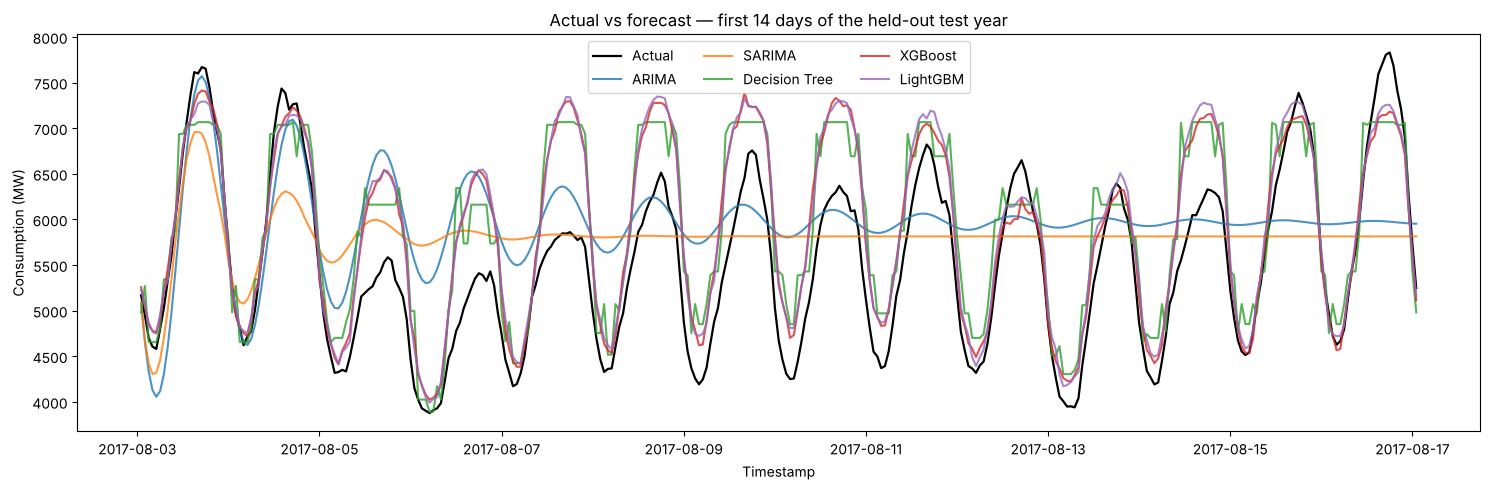

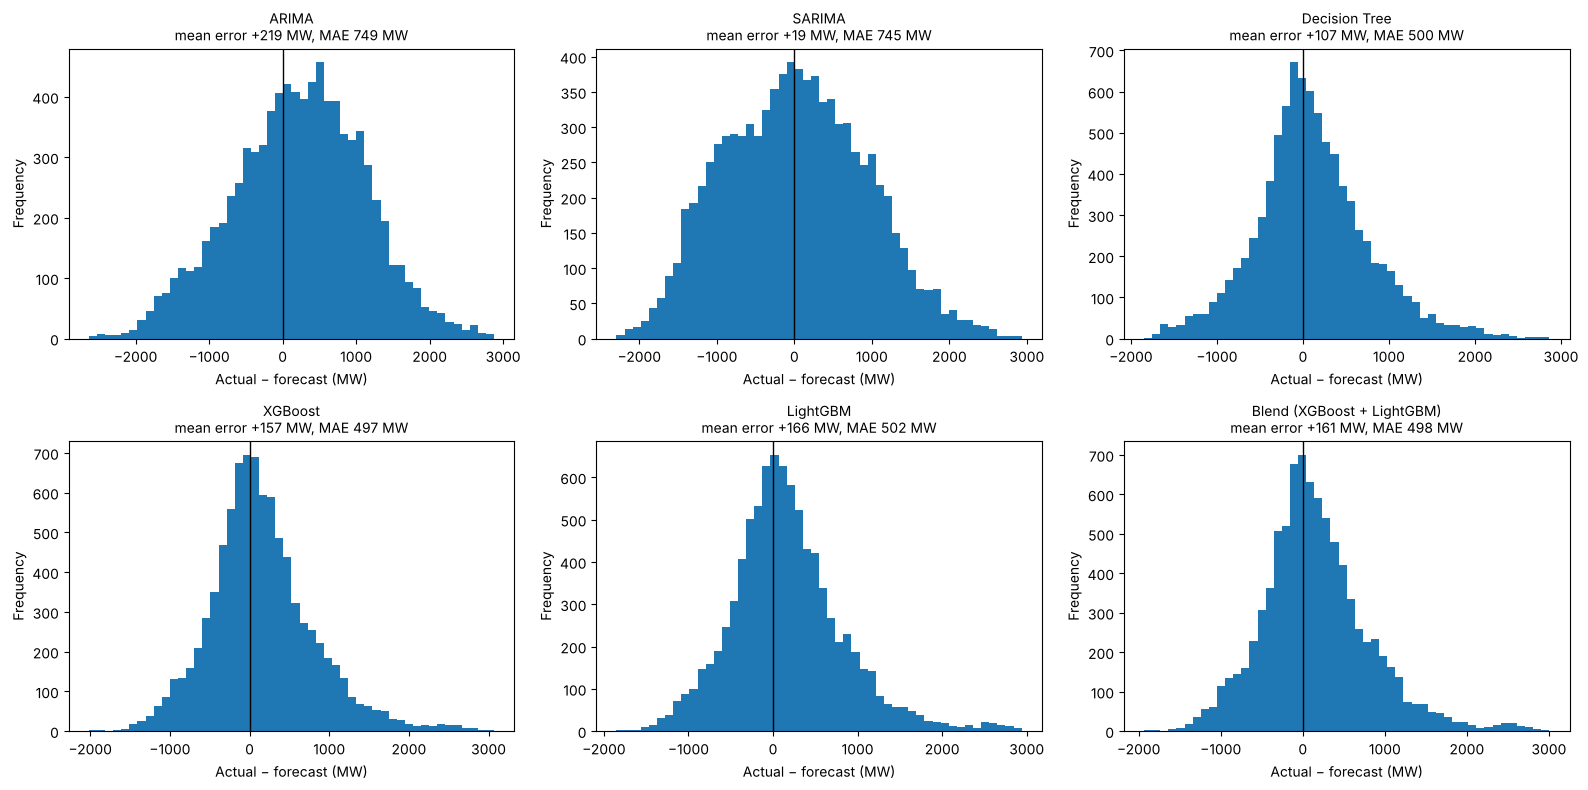

In [57]:
residual_diagnostics = []
for family in ['ARIMA', 'SARIMA']:
    resid = pd.Series(np.asarray(fitted_by_family[family].resid)).replace([np.inf, -np.inf], np.nan).dropna()
    if len(resid) > 50:
        lb = acorr_ljungbox(resid, lags=[24, 48, 168], return_df=True)
        residual_diagnostics.append({'Model': family, 'Residual mean': resid.mean(), 'Residual std': resid.std(),
                                     'Ljung-Box p-value (24)': lb.loc[24, 'lb_pvalue'],
                                     'Ljung-Box p-value (48)': lb.loc[48, 'lb_pvalue'],
                                     'Ljung-Box p-value (168)': lb.loc[168, 'lb_pvalue']})
display(pd.DataFrame(residual_diagnostics).set_index('Model').round(4))

plot_families = ['ARIMA', 'SARIMA', 'Decision Tree', 'XGBoost', 'LightGBM']
plot_idx = test_series.index[test_series.index <= test_series.index[0] + pd.Timedelta(days=14)]
plt.figure(figsize=(15, 5))
plt.plot(test_series.loc[plot_idx], label='Actual', color='black', linewidth=1.6)
for family in plot_families:
    plt.plot(test_forecasts[family].loc[plot_idx], label=family, alpha=0.8)
plt.title('Actual vs forecast — first 14 days of the held-out test year')
plt.xlabel('Timestamp'); plt.ylabel('Consumption (MW)'); plt.legend(ncol=3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, family in zip(axes.ravel(), plot_families + ['Blend (XGBoost + LightGBM)']):
    errors = test_series - test_forecasts[family]
    ax.hist(errors, bins=50)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(f'{family}\nmean error {errors.mean():+.0f} MW, MAE {errors.abs().mean():.0f} MW', fontsize=10)
    ax.set_xlabel('Actual − forecast (MW)'); ax.set_ylabel('Frequency')
plt.tight_layout(); plt.show()

## 8. Select the deployment model and explain the decision

The deployment winner is chosen from the candidate families (and the Blend) with a **multi-metric ranking on validation results only**: MAE and RMSE (MW), sMAPE and MAPE (%), MASE (error versus a seasonal-naive scale) and R². The weekly seasonal-naive benchmark is shown for reference but is not a candidate. MAE is the primary tie-breaker because it is directly interpretable in MW. Test metrics are then shown to confirm how the winner generalises — they do not change the choice.

In [58]:
# Multi-metric validation ranking: lower error metrics and higher R2 are better. Test metrics are NOT used.
selection_table = validation_family_results.drop(index='Weekly Seasonal Naive (benchmark)').copy()
rank_columns = ['MAE (MW)', 'RMSE (MW)', 'sMAPE (%)', 'MAPE (%)', 'MASE']
for metric in rank_columns:
    selection_table[f'{metric} rank'] = selection_table[metric].rank(method='min', ascending=True)
selection_table['R2 rank'] = selection_table['R2'].rank(method='min', ascending=False)
selection_table['Mean metric rank'] = selection_table[[f'{m} rank' for m in rank_columns] + ['R2 rank']].mean(axis=1)
selection_table = selection_table.sort_values(['Mean metric rank', 'MAE (MW)'])
selected_model_name = selection_table.index[0]
selection_table['Selected for deployment'] = selection_table.index == selected_model_name
print('Final deployment selection (mean validation rank across MAE, RMSE, sMAPE, MAPE, MASE and R2):', selected_model_name)
display(selection_table.round(3))

winner_test_metrics = test_results.loc[selected_model_name]
original_baseline_mae = test_results.loc['Weekly Seasonal Naive (benchmark)', 'MAE (MW)']
print('\nHeld-out test performance of the selected model:')
for metric in ['MAE (MW)', 'RMSE (MW)', 'sMAPE (%)', 'MAPE (%)', 'R2', 'MASE']:
    print(f'{metric}: {winner_test_metrics[metric]:.3f}')
print('\nInterpretation: lower MAE/RMSE/sMAPE/MAPE/MASE is better; higher R2 is better. R2 is not an accuracy percentage.')

best_test_family = test_results.drop(index='Weekly Seasonal Naive (benchmark)').index[0]
display(Markdown(
    f"**Decision.** **{selected_model_name}** ranks first on validation and reaches a held-out test MAE of **{winner_test_metrics['MAE (MW)']:.1f} MW** "
    f"(RMSE {winner_test_metrics['RMSE (MW)']:.1f} MW, MAPE {winner_test_metrics['MAPE (%)']:.2f}%), "
    f"{(1 - winner_test_metrics['MAE (MW)'] / original_baseline_mae) * 100:.1f}% lower MAE than the weekly seasonal-naive benchmark. "
    + ("It is also the best family on the test year." if best_test_family == selected_model_name else
       f"On the test year **{best_test_family}** scores {test_results.loc[best_test_family, 'MAE (MW)']:.1f} MW, only "
       f"{abs(winner_test_metrics['MAE (MW)'] - test_results.loc[best_test_family, 'MAE (MW)']):.1f} MW "
       f"({abs(winner_test_metrics['MAE (MW)'] / test_results.loc[best_test_family, 'MAE (MW)'] - 1) * 100:.1f}%) away — a statistical tie between the two boosted models. "
       "The choice stays with the validation winner so that test data never influences model selection.")))
assert selected_model_name in ML_FAMILIES + ['Blend (XGBoost + LightGBM)'], (
    'ARIMA/SARIMA cannot be served by the feature-based Streamlit backend; choose a tabular model family.')

Final deployment selection (mean validation rank across MAE, RMSE, sMAPE, MAPE, MASE and R2): LightGBM


,MAE (MW),RMSE (MW),sMAPE (%),MAPE (%),R2,MASE,MAE (MW) rank,RMSE (MW) rank,sMAPE (%) rank,MAPE (%) rank,MASE rank,R2 rank,Mean metric rank,Selected for deployment
Model family,,,,,,,,,,,,,,
LightGBM,449.925,610.675,7.927,7.833,0.607,0.922,1.0,1.0,1.0,1.0,1.0,1.0,1.0,True
Blend (XGBoost + LightGBM),451.781,611.347,7.958,7.859,0.606,0.926,2.0,2.0,2.0,2.0,2.0,2.0,2.0,False
XGBoost,457.085,616.017,8.054,7.950,0.600,0.936,3.0,3.0,3.0,3.0,3.0,3.0,3.0,False
Decision Tree,496.825,661.171,8.792,8.712,0.540,1.018,4.0,4.0,4.0,4.0,4.0,4.0,4.0,False
SARIMA,718.890,911.626,12.920,13.202,0.125,1.473,5.0,5.0,5.0,5.0,5.0,5.0,5.0,False
ARIMA,763.724,975.713,13.867,13.467,-0.002,1.565,6.0,6.0,6.0,6.0,6.0,6.0,6.0,False



Held-out test performance of the selected model:
MAE (MW): 502.130
RMSE (MW): 681.306
sMAPE (%): 8.577
MAPE (%): 8.354
R2: 0.530
MASE: 1.015

Interpretation: lower MAE/RMSE/sMAPE/MAPE/MASE is better; higher R2 is better. R2 is not an accuracy percentage.


**Decision.** **LightGBM** ranks first on validation and reaches a held-out test MAE of **502.1 MW** (RMSE 681.3 MW, MAPE 8.35%), 20.1% lower MAE than the weekly seasonal-naive benchmark. On the test year **XGBoost** scores 497.1 MW, only 5.1 MW (1.0%) away — a statistical tie between the two boosted models. The choice stays with the validation winner so that test data never influences model selection.

### Where does the selected model make its errors?

Understanding *when* the model is wrong is as important as the headline MAE. The three views below use the held-out test forecasts of the selected model: error by **forecast day ahead** (days 1–30 of each block), by **hour of day** and by **calendar month**.

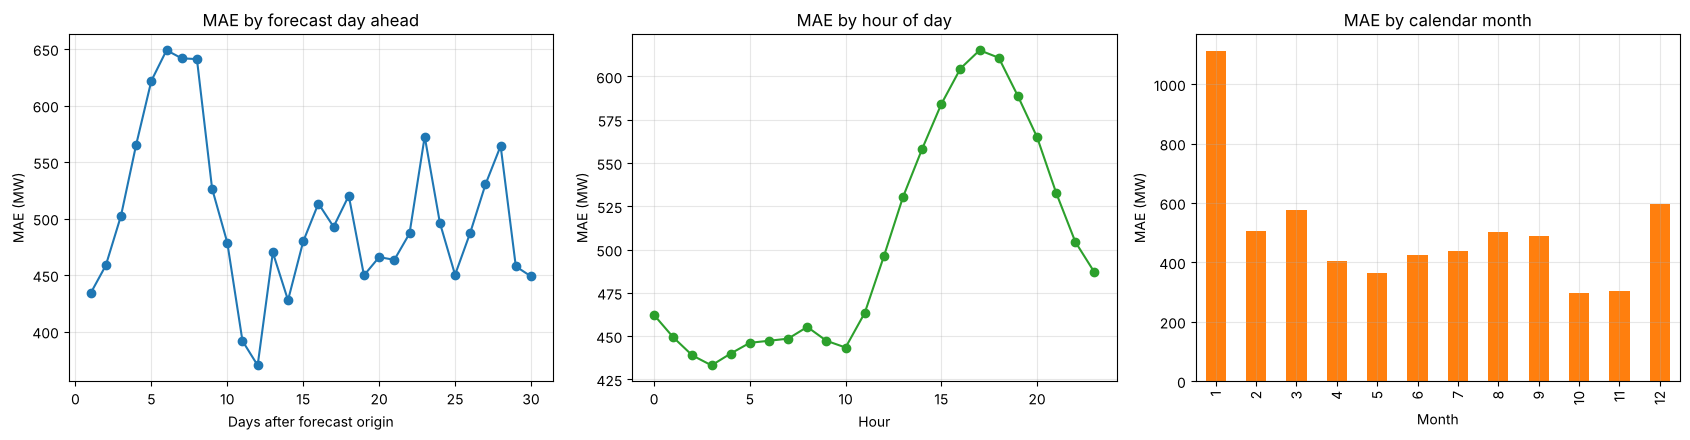

**Findings.** (1) Day 1 of a forecast has MAE **434 MW**, rising to ≈ **496 MW** over the last ten days — after the first few days the model can no longer 'see' the weather, so it relies on seasonal and calendar patterns. (2) The hardest month is **January** (1112 MW) and the easiest is **October** (297 MW): summer and winter demand is driven by temperature extremes (air-conditioning and heating), which calendar features alone cannot anticipate. (3) Errors are largest around hour **17:00** (615 MW) and smallest around hour **3:00** (433 MW). (4) Mean forecast bias on the test year is **+166 MW** (actual − forecast; a positive value means the model slightly under-forecasts on average, i.e. 2.9% of average demand).

In [59]:
sel_pred = test_forecasts[selected_model_name]
err = pd.DataFrame({'actual': test_series, 'pred': sel_pred})
err['abs_error'] = (err['actual'] - err['pred']).abs()
err['pct_error'] = err['abs_error'] / err['actual'] * 100
err['position_in_block'] = np.concatenate([np.arange(len(b)) for b in TEST_BLOCKS])
err['day_ahead'] = err['position_in_block'] // 24 + 1
err['hour'] = err.index.hour
err['month'] = err.index.month

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
err.groupby('day_ahead')['abs_error'].mean().plot(ax=axes[0], marker='o')
axes[0].set_title('MAE by forecast day ahead'); axes[0].set_xlabel('Days after forecast origin'); axes[0].set_ylabel('MAE (MW)')
err.groupby('hour')['abs_error'].mean().plot(ax=axes[1], marker='o', color='tab:green')
axes[1].set_title('MAE by hour of day'); axes[1].set_xlabel('Hour'); axes[1].set_ylabel('MAE (MW)')
err.groupby('month')['abs_error'].mean().plot(ax=axes[2], kind='bar', color='tab:orange')
axes[2].set_title('MAE by calendar month'); axes[2].set_xlabel('Month'); axes[2].set_ylabel('MAE (MW)')
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

by_day = err.groupby('day_ahead')['abs_error'].mean()
by_month = err.groupby('month')['abs_error'].mean()
by_hour = err.groupby('hour')['abs_error'].mean()
display(Markdown(
    f"**Findings.** (1) Day 1 of a forecast has MAE **{by_day.iloc[0]:.0f} MW**, rising to ≈ **{by_day.iloc[-10:].mean():.0f} MW** over the last ten days — "
    "after the first few days the model can no longer 'see' the weather, so it relies on seasonal and calendar patterns. "
    f"(2) The hardest month is **{calendar.month_name[by_month.idxmax()]}** ({by_month.max():.0f} MW) and the easiest is **{calendar.month_name[by_month.idxmin()]}** ({by_month.min():.0f} MW): "
    "summer and winter demand is driven by temperature extremes (air-conditioning and heating), which calendar features alone cannot anticipate. "
    f"(3) Errors are largest around hour **{by_hour.idxmax()}:00** ({by_hour.max():.0f} MW) and smallest around hour **{by_hour.idxmin()}:00** ({by_hour.min():.0f} MW). "
    f"(4) Mean forecast bias on the test year is **{(err['actual'] - err['pred']).mean():+.0f} MW** (actual − forecast; a positive value means the model slightly under-forecasts on average, "
    f"i.e. {(err['actual'] - err['pred']).mean() / err['actual'].mean() * 100:.1f}% of average demand)."))

### Overall test-year view

Daily average demand — actual versus the selected model — shows whether the model tracks the seasonal cycle and the year-to-year level over the whole held-out year.

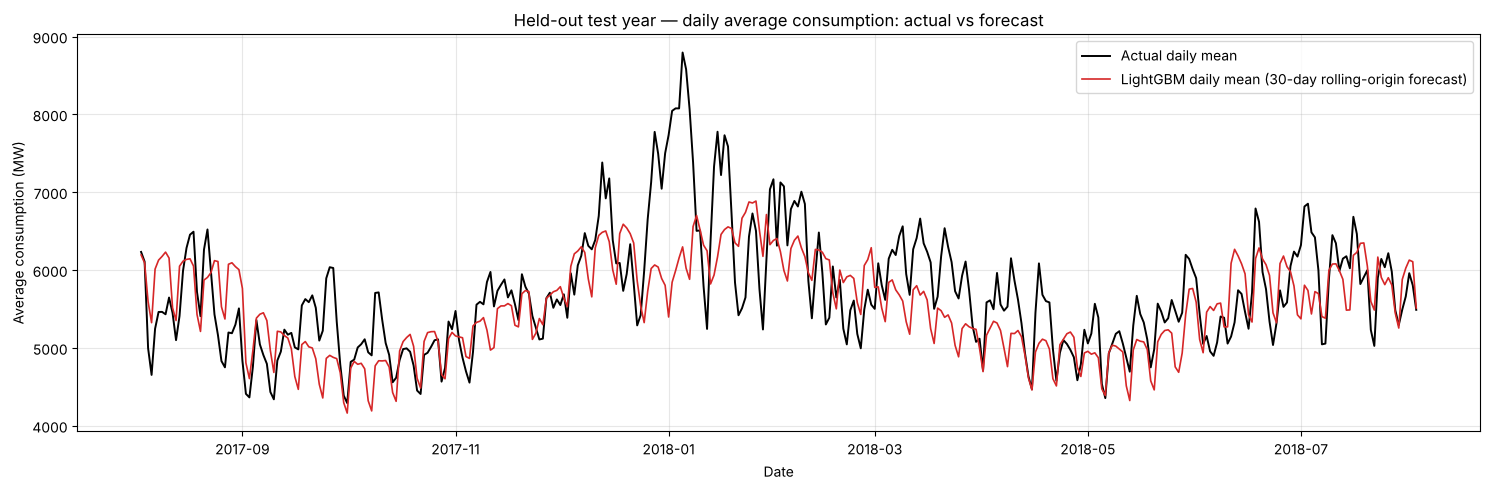

Daily-average MAE: 467.9 MW


In [60]:
daily = pd.DataFrame({'Actual': test_series, selected_model_name: sel_pred}).resample('D').mean()
plt.figure(figsize=(15, 5))
plt.plot(daily.index, daily['Actual'], label='Actual daily mean', color='black', linewidth=1.4)
plt.plot(daily.index, daily[selected_model_name], label=f'{selected_model_name} daily mean (30-day rolling-origin forecast)', color='tab:red', linewidth=1.2)
plt.title('Held-out test year — daily average consumption: actual vs forecast')
plt.xlabel('Date'); plt.ylabel('Average consumption (MW)'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print(f"Daily-average MAE: {(daily['Actual'] - daily[selected_model_name]).abs().mean():.1f} MW")

## 9. Refit the selected model on all available history and forecast the next 30 days

The selected model family and its validation-selected configuration are refitted on **all** history and used to generate the required **720 hourly point forecasts** after the last observed timestamp. Every hour is predicted directly from the last observed hour, calendar and holiday features. Since this historical dataset ends in 2018, the forecast dates continue that historical dataset — they are not a forecast for today's date.

Selected model: LightGBM
Training examples used for the final fit: 249,337
Forecast rows: 720
Forecast horizon: 2018-08-03 01:00:00 to 2018-09-02 00:00:00


,Datetime,Forecast_PJMW_MW
0,2018-08-03 01:00:00,5111.330795
1,2018-08-03 02:00:00,4775.207711
2,2018-08-03 03:00:00,4670.392182
3,2018-08-03 04:00:00,4533.064925
4,2018-08-03 05:00:00,4554.119535
5,2018-08-03 06:00:00,4763.798358
6,2018-08-03 07:00:00,4954.652463
7,2018-08-03 08:00:00,5285.547100
8,2018-08-03 09:00:00,5627.979446
9,2018-08-03 10:00:00,5896.605112


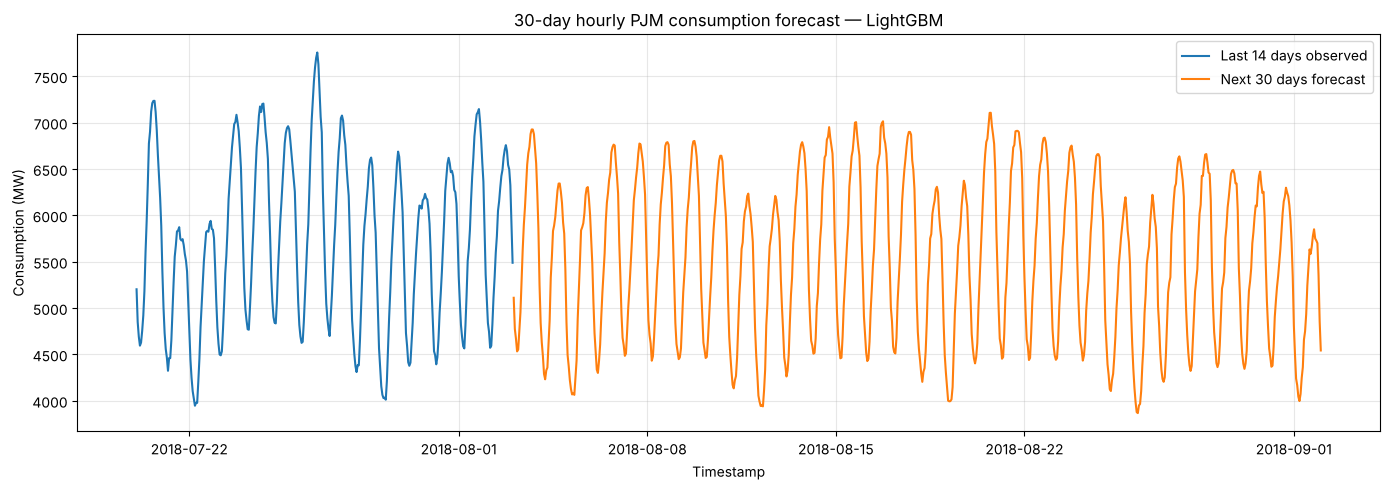

In [61]:
full_history = model_data.copy()
future_index = pd.date_range(full_history.index[-1] + pd.Timedelta(hours=1), periods=HORIZON, freq='h')

if selected_model_name == 'Blend (XGBoost + LightGBM)':
    from model_deployment import AverageEnsemble        # defined in model_deployment.py so the app can load the saved file
    members = [fit_ml_model(f, selected_configs[f], full_history) for f in ['XGBoost', 'LightGBM']]
    deployment_model = AverageEnsemble(members)
    selected_config = {f: selected_configs[f] for f in ['XGBoost', 'LightGBM']}
    training_rows = members[0].n_training_rows_
else:
    deployment_model = fit_ml_model(selected_model_name, selected_configs[selected_model_name], full_history)
    selected_config = selected_configs[selected_model_name]
    training_rows = deployment_model.n_training_rows_

future_prediction = forecast_ml_block(deployment_model, full_history, future_index)
future_forecast_df = pd.DataFrame({'Datetime': future_index, 'Forecast_PJMW_MW': future_prediction})
assert len(future_forecast_df) == HORIZON
assert future_forecast_df['Datetime'].is_monotonic_increasing and future_forecast_df['Datetime'].is_unique
assert future_forecast_df['Forecast_PJMW_MW'].notna().all()
print('Selected model:', selected_model_name)
print('Training examples used for the final fit:', f'{training_rows:,}')
print('Forecast rows:', len(future_forecast_df))
print('Forecast horizon:', future_forecast_df['Datetime'].min(), 'to', future_forecast_df['Datetime'].max())
display(future_forecast_df.head(10))

plt.figure(figsize=(14, 5))
plt.plot(full_history.tail(24 * 14).index, full_history.tail(24 * 14).values, label='Last 14 days observed')
plt.plot(future_index, future_forecast_df['Forecast_PJMW_MW'], label='Next 30 days forecast')
plt.title(f'30-day hourly PJM consumption forecast — {selected_model_name}')
plt.xlabel('Timestamp'); plt.ylabel('Consumption (MW)'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Sanity check — does the 30-day forecast look plausible?

A forecast should resemble what happened in the same calendar period of earlier years. The forecast window (4 Aug – 2 Sep) is compared with the same 30 days of the previous three years; the forecast should sit inside the range of those years and keep the same daily shape.

,Period,Mean (MW),Min (MW),Max (MW)
0,03 Aug 2017 – 02 Sep 2017 (actual),5547.7,3840.0,8126.0
1,03 Aug 2016 – 02 Sep 2016 (actual),6240.1,3997.0,8637.0
2,03 Aug 2015 – 02 Sep 2015 (actual),5625.4,3692.0,8256.0
3,03 Aug 2018 – 02 Sep 2018 (forecast),5538.5,3867.7,7107.1


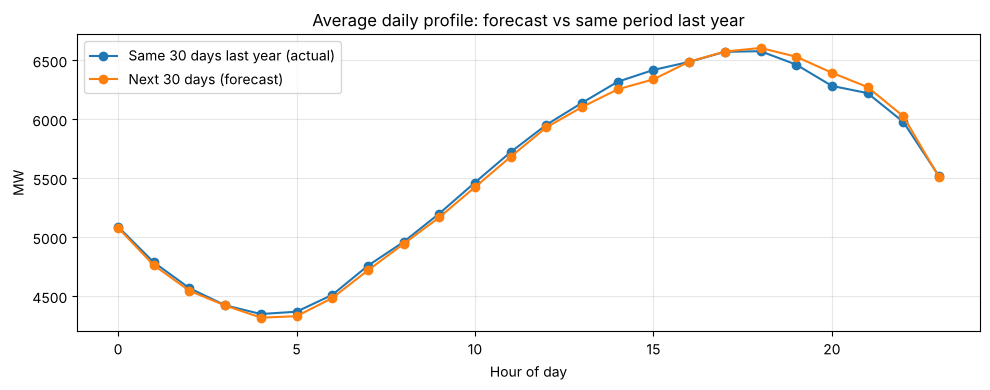

**Finding.** The forecast averages **5,539 MW** (range 3,868–7,107 MW) against 5,548 MW for the same period last year (range 3,840–8,126 MW). It keeps the daily evening peak / overnight trough shape and the weekday-weekend rhythm and does not drift or collapse over the 30 days. As expected for a point forecast made without weather data, the forecast peaks are smoother than real heat-wave extremes — the model predicts the typical demand for those dates, not the weather.

In [62]:
rows = []
for years_back in (1, 2, 3):
    start = future_index[0] - pd.DateOffset(years=years_back)
    ref = model_data.loc[start: start + pd.Timedelta(hours=HORIZON - 1)]
    rows.append({'Period': f'{ref.index[0]:%d %b %Y} – {ref.index[-1]:%d %b %Y} (actual)', 'Mean (MW)': ref.mean(), 'Min (MW)': ref.min(), 'Max (MW)': ref.max()})
fc = future_forecast_df['Forecast_PJMW_MW']
rows.append({'Period': f'{future_index[0]:%d %b %Y} – {future_index[-1]:%d %b %Y} (forecast)', 'Mean (MW)': fc.mean(), 'Min (MW)': fc.min(), 'Max (MW)': fc.max()})
sanity = pd.DataFrame(rows)
display(sanity.round(1))

fc_profile = future_forecast_df.assign(hour=future_forecast_df['Datetime'].dt.hour).groupby('hour')['Forecast_PJMW_MW'].mean()
ref_last_year = model_data.loc[future_index[0] - pd.DateOffset(years=1): future_index[0] - pd.DateOffset(years=1) + pd.Timedelta(hours=HORIZON - 1)]
ref_profile = ref_last_year.groupby(ref_last_year.index.hour).mean()
plt.figure(figsize=(10, 4))
plt.plot(ref_profile.index, ref_profile.values, marker='o', label='Same 30 days last year (actual)')
plt.plot(fc_profile.index, fc_profile.values, marker='o', label='Next 30 days (forecast)')
plt.title('Average daily profile: forecast vs same period last year'); plt.xlabel('Hour of day'); plt.ylabel('MW'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Finding.** The forecast averages **{fc.mean():,.0f} MW** (range {fc.min():,.0f}–{fc.max():,.0f} MW) against {rows[0]['Mean (MW)']:,.0f} MW for the same period last year "
    f"(range {rows[0]['Min (MW)']:,.0f}–{rows[0]['Max (MW)']:,.0f} MW). It keeps the daily evening peak / overnight trough shape and the weekday-weekend rhythm and does not drift or collapse over the 30 days. "
    "As expected for a point forecast made without weather data, the forecast peaks are smoother than real heat-wave extremes — the model predicts the typical demand for those dates, not the weather."))

## 10. What drives the forecasts? (feature importance)

Tree-based importance shows which inputs the selected model relies on most. It describes the fitted model, not a causal effect.

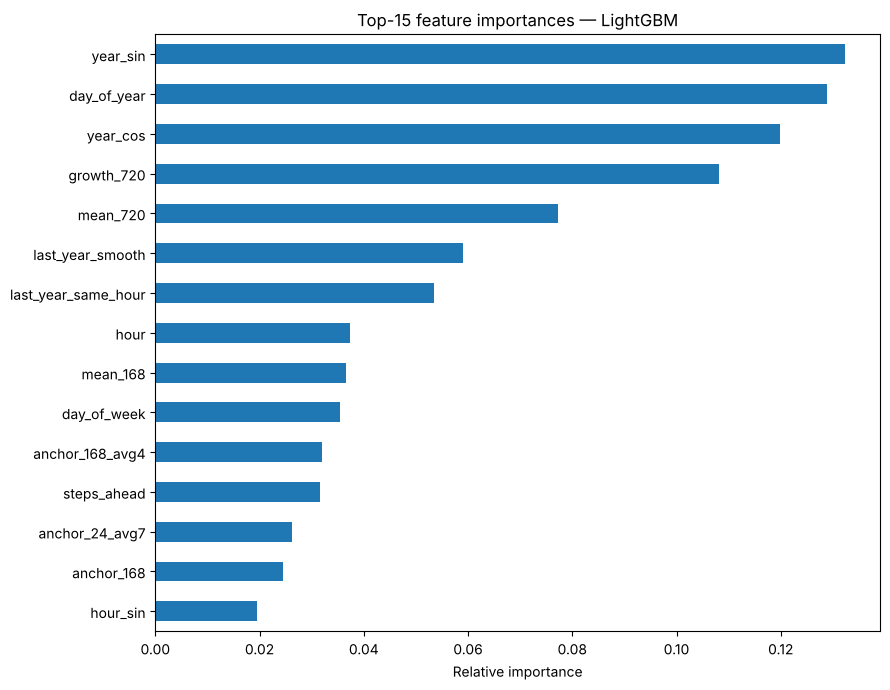

**Finding.** The five most influential inputs are: `year_sin` (13.2%), `day_of_year` (12.9%), `year_cos` (12.0%), `growth_720` (10.8%), `mean_720` (7.7%). This agrees with the EDA: the time of year (seasonal cycle) and the recent demand level / year-on-year growth carry most of the signal, while holiday flags matter on only a few days a year. Hour-of-day and day-of-week effects are spread across several features (`hour`, `hour_sin/cos`, `anchor_24`, `anchor_168`, `is_weekend`).

In [63]:
def model_importances(model):
    if hasattr(model, 'feature_importances_'):
        imp = np.asarray(model.feature_importances_, dtype=float)
        return pd.Series(imp / imp.sum(), index=FEATURES)
    raise ValueError('Model has no feature importances.')

importance = model_importances(deployment_model).sort_values(ascending=True)
plt.figure(figsize=(9, 7))
importance.tail(15).plot(kind='barh', color='tab:blue')
plt.title(f'Top-15 feature importances — {selected_model_name}'); plt.xlabel('Relative importance'); plt.tight_layout(); plt.show()
top5 = importance.sort_values(ascending=False).head(5)
display(Markdown('**Finding.** The five most influential inputs are: ' + ', '.join(f'`{n}` ({v:.1%})' for n, v in top5.items()) +
                 '. This agrees with the EDA: the time of year (seasonal cycle) and the recent demand level / year-on-year growth carry most of the signal, while holiday flags matter on only a few days a year. '
                 'Hour-of-day and day-of-week effects are spread across several features (`hour`, `hour_sin/cos`, `anchor_24`, `anchor_168`, `is_weekend`).'))

## 11. Save deployment and audit artifacts

The three files the Streamlit app needs are saved **next to the notebook (beside `app.py`)**: the fitted model (`.joblib`), the cleaned hourly history (`.csv`) and the metadata (`.json`). Evaluation tables and forecasts are saved in the `PJM_Forecasting_Artifacts` folder for audit. These files are reproducibility artifacts; monitoring and retraining are required before any live operational use.

In [64]:
app_dir = Path('.')                                         # deployment files go beside app.py / model_deployment.py
audit_dir = Path('PJM_Forecasting_Artifacts'); audit_dir.mkdir(parents=True, exist_ok=True)

# ---- audit artifacts -------------------------------------------------------------------------
validation_tuning_results.to_csv(audit_dir / 'PJM_validation_tuning_results.csv', index=False)
validation_family_results.to_csv(audit_dir / 'PJM_validation_family_comparison.csv')
test_results.to_csv(audit_dir / 'PJM_heldout_test_metrics.csv')
test_forecast_df = pd.DataFrame({'Actual': test_series})
for family, pred in test_forecasts.items():
    test_forecast_df[family] = pred
test_forecast_df.to_csv(audit_dir / 'PJM_heldout_test_forecasts.csv', index_label='Datetime')
future_forecast_df.to_csv(audit_dir / 'PJM_next_30_days_hourly_forecast.csv', index=False)

# ---- deployment artifacts (read by model_deployment.py / app.py) -------------------------------
joblib.dump(deployment_model, app_dir / 'PJM_selected_deployment_model.joblib')
full_history.rename('PJMW_MW').rename_axis('Datetime').reset_index().to_csv(app_dir / 'PJMW_MW_cleaned_hourly_history.csv', index=False)
with open(app_dir / 'PJM_tree_feature_columns.json', 'w', encoding='utf-8') as f:
    json.dump(FEATURES, f, indent=2)

metadata = {
    'target': 'PJMW_MW', 'frequency': 'hourly', 'selected_model': selected_model_name,
    'selected_configuration': selected_config,
    'selection_metric': 'mean validation rank across MAE, RMSE, sMAPE, MAPE, MASE and R2 (12 validation windows)',
    'forecasting_approach': 'direct multi-horizon (every hour predicted from the last observation, calendar/holiday features and anchored lags)',
    'validation_windows': len(VALIDATION_WINDOWS), 'validation_horizon_hours': HORIZON,
    'test_horizon_hours': len(test_series), 'test_blocks': len(TEST_BLOCKS), 'forecast_horizon_hours': HORIZON,
    'training_window_days': int((full_history.index[-1] - full_history.index[0]).days),
    'training_rows': int(training_rows),
    'heldout_test_metrics_from_notebook': {
        'MAE_MW': float(winner_test_metrics['MAE (MW)']), 'RMSE_MW': float(winner_test_metrics['RMSE (MW)']),
        'MAPE_percent': float(winner_test_metrics['MAPE (%)']), 'R2': float(winner_test_metrics['R2']),
        'sMAPE_percent': float(winner_test_metrics['sMAPE (%)']), 'MASE': float(winner_test_metrics['MASE']),
    },
    'validation_metrics': {k: float(v) for k, v in validation_family_results.loc[selected_model_name, ['MAE (MW)', 'RMSE (MW)', 'MAPE (%)', 'R2']].items()},
    'last_observed_timestamp': str(full_history.index[-1]),
    'forecast_start': str(future_index[0]), 'forecast_end': str(future_index[-1]),
    'feature_columns': FEATURES,
    'note': 'Historical continuation based on the dataset end date; refresh data before live deployment.'
}
with open(app_dir / 'PJM_deployment_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)

print('Saved deployment files to:', app_dir.resolve())
for name in ['PJM_selected_deployment_model.joblib', 'PJMW_MW_cleaned_hourly_history.csv', 'PJM_deployment_metadata.json', 'PJM_tree_feature_columns.json']:
    print('-', name, f'({(app_dir / name).stat().st_size:,} bytes)')
print('Saved audit files to:', audit_dir.resolve())
for p in sorted(audit_dir.iterdir()): print('-', p.name, f'({p.stat().st_size:,} bytes)')

Saved deployment files to: /home/claude/work
- PJM_selected_deployment_model.joblib (1,158,421 bytes)
- PJMW_MW_cleaned_hourly_history.csv (3,862,718 bytes)
- PJM_deployment_metadata.json (1,929 bytes)
- PJM_tree_feature_columns.json (422 bytes)
Saved audit files to: /home/claude/work/PJM_Forecasting_Artifacts
- PJM_heldout_test_forecasts.csv (1,222,381 bytes)
- PJM_heldout_test_metrics.csv (1,070 bytes)
- PJM_next_30_days_hourly_forecast.csv (27,388 bytes)
- PJM_validation_family_comparison.csv (943 bytes)
- PJM_validation_tuning_results.csv (2,864 bytes)


## 12. Verify that the notebook and the Streamlit backend agree

The app uses `model_deployment.py`. As a final safeguard, the saved model and history are reloaded **through that module** and the 30-day forecast it produces is compared with the notebook forecast. They must be identical — otherwise the live app would not reproduce the notebook results.

In [65]:
import importlib, model_deployment
importlib.reload(model_deployment)

dep_model = model_deployment.load_model()
dep_history = model_deployment.load_history()
dep_meta = model_deployment.load_metadata()
assert model_deployment.FEATURES == FEATURES, 'Feature list differs between notebook and model_deployment.py'
assert np.allclose(dep_history.values, full_history.values) and dep_history.index.equals(full_history.index), 'History mismatch'

dep_forecast = model_deployment.forecast_hours(dep_model, dep_history, HORIZON)
max_diff = float(np.max(np.abs(dep_forecast['Predicted_MW'].values - future_forecast_df['Forecast_PJMW_MW'].values)))
print(f'Maximum absolute difference between notebook and app-backend forecasts: {max_diff:.6f} MW')
assert max_diff < 1e-6, 'Notebook forecast and app-backend forecast differ'

# Shorter horizons used by the app slider must also work and be consistent prefixes of the 30-day forecast.
for days in (1, 7, 14):
    short = model_deployment.forecast_hours(dep_model, dep_history, days * 24)
    assert len(short) == days * 24
    assert np.allclose(short['Predicted_MW'].values, dep_forecast['Predicted_MW'].values[:days * 24])
print('Horizon checks (1, 7, 14 and 30 days) passed.')
print('Model loaded by the app backend:', type(dep_model).__name__, '| metadata model:', dep_meta['selected_model'])
display(Markdown('**Verified.** The Streamlit backend reproduces the notebook forecast exactly. Run the app with `streamlit run app.py` from this folder.'))

Maximum absolute difference between notebook and app-backend forecasts: 0.000000 MW


Horizon checks (1, 7, 14 and 30 days) passed.
Model loaded by the app backend: LGBMRegressor | metadata model: LightGBM


**Verified.** The Streamlit backend reproduces the notebook forecast exactly. Run the app with `streamlit run app.py` from this folder.

## 13. Final findings, conclusion and deployment checklist

In [66]:
sel_val = validation_family_results.loc[selected_model_name]
sel_test = test_results.loc[selected_model_name]
bench_test = test_results.loc['Weekly Seasonal Naive (benchmark)']
rank_test = test_results.drop(index='Weekly Seasonal Naive (benchmark)')
summary = pd.concat([
    validation_family_results[['MAE (MW)', 'RMSE (MW)', 'MAPE (%)', 'R2']].add_prefix('Validation '),
    test_results[['MAE (MW)', 'RMSE (MW)', 'MAPE (%)', 'R2']].add_prefix('Test ')], axis=1).sort_values('Test MAE (MW)')
display(summary.round(3))
display(Markdown(f"""
### Conclusions

- **Best model:** **{selected_model_name}** was selected on validation evidence only (12 monthly forecast windows) and then confirmed on the untouched final year:
  **MAE {sel_test['MAE (MW)']:.1f} MW, RMSE {sel_test['RMSE (MW)']:.1f} MW, MAPE {sel_test['MAPE (%)']:.2f}%, sMAPE {sel_test['sMAPE (%)']:.2f}%, R² {sel_test['R2']:.3f}**
  (validation MAE {sel_val['MAE (MW)']:.1f} MW).
- **Versus the earlier version of this notebook:** the earlier recursive XGBoost reached a held-out test MAE of 545.2 MW / RMSE 721.7 MW / MAPE 9.09%; the selected model improves this to {sel_test['MAE (MW)']:.1f} MW / {sel_test['RMSE (MW)']:.1f} MW / {sel_test['MAPE (%)']:.2f}%
  ({(1 - sel_test['MAE (MW)'] / 545.249) * 100:.1f}% lower MAE, {(1 - sel_test['RMSE (MW)'] / 721.723) * 100:.1f}% lower RMSE) and its validation MAE is {sel_val['MAE (MW)']:.1f} MW compared with 563.8 MW before.
- **Versus simple benchmarks:** the weekly seasonal-naive benchmark has a test MAE of {bench_test['MAE (MW)']:.1f} MW; the selected model reduces this by **{(1 - sel_test['MAE (MW)'] / bench_test['MAE (MW)']) * 100:.1f}%**.
  ARIMA and SARIMA reach test MAE of {test_results.loc['ARIMA', 'MAE (MW)']:.0f} and {test_results.loc['SARIMA', 'MAE (MW)']:.0f} MW — they only see two weeks of history and cannot represent yearly seasonality or holidays.
- **Why the improvement:** (1) every hour of the 30-day horizon is predicted *directly* from the last observation, calendar/holiday features and yearly-anchored values, so errors do not compound as in recursive forecasting; (2) holiday flags and 52-week-earlier demand were added;
  (3) models are trained on the full history with randomly sampled (origin, horizon) pairs; (4) loss functions and tree sizes were compared on twelve validation windows.
- **Patterns found (consistent with the EDA):** strong daily and weekly cycles (autocorrelation {acf_values[24]:.2f} at 24 h and {acf_values[168]:.2f} at 168 h), higher and more volatile demand in summer and winter, lower demand on weekends and federal holidays.
- **Limits of accuracy:** demand is weather-driven and no weather data is available, so beyond the first few days the forecast follows seasonal/calendar patterns and cannot anticipate heat waves or cold snaps. Typical hourly error is about {sel_test['MAPE (%)']:.1f}% of demand.
  The forecasts are point estimates without prediction intervals.
- **Forecast delivered:** 720 hourly values from {future_index[0]:%d %b %Y %H:%M} to {future_index[-1]:%d %b %Y %H:%M}, saved in `PJM_Forecasting_Artifacts/PJM_next_30_days_hourly_forecast.csv` and served by the Streamlit app.

### Scope note
The source data ends on **{full_history.index[-1]:%Y-%m-%d}**. The generated 30-day forecast therefore starts immediately after that timestamp; it is **not** a forecast for the current date.

### Before any live use
Refresh the dataset, rerun the chronological validation, check timestamp/time-zone conventions, add weather (temperature) as an external feature — the largest remaining source of error — monitor drift and forecast error, and set a retraining schedule.
"""))

,Validation MAE (MW),Validation RMSE (MW),Validation MAPE (%),Validation R2,Test MAE (MW),Test RMSE (MW),Test MAPE (%),Test R2
XGBoost,457.085,616.017,7.950,0.600,497.071,674.929,8.270,0.539
Blend (XGBoost + LightGBM),451.781,611.347,7.859,0.606,498.247,676.558,8.287,0.536
Decision Tree,496.825,661.171,8.712,0.540,500.487,668.514,8.449,0.547
LightGBM,449.925,610.675,7.833,0.607,502.130,681.306,8.354,0.530
Weekly Seasonal Naive (benchmark),623.260,863.515,10.778,0.215,628.634,827.420,10.623,0.307
SARIMA,718.890,911.626,13.202,0.125,744.639,911.794,13.424,0.158
ARIMA,763.724,975.713,13.467,-0.002,748.708,927.184,13.115,0.129



### Conclusions

- **Best model:** **LightGBM** was selected on validation evidence only (12 monthly forecast windows) and then confirmed on the untouched final year:
  **MAE 502.1 MW, RMSE 681.3 MW, MAPE 8.35%, sMAPE 8.58%, R² 0.530**
  (validation MAE 449.9 MW).
- **Versus the earlier version of this notebook:** the earlier recursive XGBoost reached a held-out test MAE of 545.2 MW / RMSE 721.7 MW / MAPE 9.09%; the selected model improves this to 502.1 MW / 681.3 MW / 8.35%
  (7.9% lower MAE, 5.6% lower RMSE) and its validation MAE is 449.9 MW compared with 563.8 MW before.
- **Versus simple benchmarks:** the weekly seasonal-naive benchmark has a test MAE of 628.6 MW; the selected model reduces this by **20.1%**.
  ARIMA and SARIMA reach test MAE of 749 and 745 MW — they only see two weeks of history and cannot represent yearly seasonality or holidays.
- **Why the improvement:** (1) every hour of the 30-day horizon is predicted *directly* from the last observation, calendar/holiday features and yearly-anchored values, so errors do not compound as in recursive forecasting; (2) holiday flags and 52-week-earlier demand were added;
  (3) models are trained on the full history with randomly sampled (origin, horizon) pairs; (4) loss functions and tree sizes were compared on twelve validation windows.
- **Patterns found (consistent with the EDA):** strong daily and weekly cycles (autocorrelation 0.87 at 24 h and 0.68 at 168 h), higher and more volatile demand in summer and winter, lower demand on weekends and federal holidays.
- **Limits of accuracy:** demand is weather-driven and no weather data is available, so beyond the first few days the forecast follows seasonal/calendar patterns and cannot anticipate heat waves or cold snaps. Typical hourly error is about 8.4% of demand.
  The forecasts are point estimates without prediction intervals.
- **Forecast delivered:** 720 hourly values from 03 Aug 2018 01:00 to 02 Sep 2018 00:00, saved in `PJM_Forecasting_Artifacts/PJM_next_30_days_hourly_forecast.csv` and served by the Streamlit app.

### Scope note
The source data ends on **2018-08-03**. The generated 30-day forecast therefore starts immediately after that timestamp; it is **not** a forecast for the current date.

### Before any live use
Refresh the dataset, rerun the chronological validation, check timestamp/time-zone conventions, add weather (temperature) as an external feature — the largest remaining source of error — monitor drift and forecast error, and set a retraining schedule.
